In [1]:
!pip install xlwt

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.0/100.0 kB 962.4 kB/s eta 0:00:00


In [2]:
from google.colab import files
import io
import os
from tqdm import tqdm
import csv

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots

zzz=np.random.randint(1,100)

In [3]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)


Mounted at /content/drive/


# Import Data

In [5]:
##UPDATED - MD. Make sure you copy the folder to your personal drive

#'drive/My Drive/ECI Research/Fall 2022/Data/'
root_path = 'drive/My Drive/ECI/ECI Research/Fall 2022/Data/'

# Read input
#uploaded = files.upload()
df = pd.read_csv(root_path+'2019-2021 cleaned/2019clean.csv')
df1_cl= pd.read_csv(root_path+'2019-2021 cleaned/2019clean.csv', index_col=0)
#uploaded = files.upload()
df2 = pd.read_csv(root_path+'2019-2021 cleaned/2020clean.csv')
df2_cl= pd.read_csv(root_path+'2019-2021 cleaned/2020clean.csv', index_col=0)

df3 = pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv')
df3_cl= pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv', index_col=0)

df7 = pd.read_csv(root_path+'GDP4.csv')
df7 = df7.drop(columns = ['Country Code', 'Series Name'])
df7 = df7.dropna()
#df7_cl = pd.read_csv(root_path+'GDP4.csv', index_col=0)
#df7_cl = df7_cl.drop(columns = ['Country Code', 'Indicator Name']) #or "Series Name"



In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
def df_to_matrix(dfa):
  raw_matrixa = dfa.to_numpy()
  matrixa = [list(dfa.columns)]

  for row in raw_matrixa:
    
    stripped=np.char.strip(np.array(row[1::]).astype(str),chars='_')
    if np.min(stripped.astype(float)) > 0:
      matrixa.append(list(row))

  return matrixa

In [8]:
## UPDATED - MD: needed to deal with non-numeric str and NAN for df7 (GDP4 file)
# equivalent to df_to_matrix(dfa)

def df7_to_matrix(df7_cl):
    temp = df7_cl.dropna()

    # Create an empty dictionary
    gdp_19to21_dict = {}

    # Iterate over the rows of the data frame
    for index, row in temp.iterrows():
      # Get the country name
      country = row['Country Name']
      
      # Get the values for 2019, 2020, and 2021
      value_2019 = row['2019']
      value_2019 = str(value_2019) #convert to str to test if isnumeric()
      value_2020 = row['2020']
      value_2020 = str(value_2020)
      value_2021 = row['2021']
      value_2021 = str(value_2021)

        # Check if the string contains only numeric characters
      if value_2019.isnumeric():
        value_2019 = float(value_2019)
      else:
      # Remove any non-numeric characters from the string
        value_2019 = None

      if value_2020.isnumeric():
        value_2020 = float(value_2020)
      else:
        value_2020 = None

      if value_2021.isnumeric():
        value_2021 = float(value_2021)
      else:
        value_2021 = None

      # Add a new entry to the dictionary with the country as the key
      # and the values for 2019, 2020, and 2021 as the values
      gdp_19to21_dict[country] = [(2019, value_2019), (2020, value_2020), (2021, value_2021)]

    # The output dictionary should now have an entry for each country in the data frame
    return gdp_19to21_dict

In [9]:
#UPDATED
matrix = df_to_matrix(df) #for 2019
matrix2 = df_to_matrix(df2) #for 2020
matrix3 = df_to_matrix(df3) #for 2021

## Clean matrix
# for GDP up to 2021 including
matrix7 = df7_to_matrix(df7) #for GDP up to 2021 including
gdp_19to21_dict = matrix7

In [ ]:
#matrix3

# ECI & PCI

MCP

In [10]:
#compute mcp

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])
    
  country_sum = []
  for i in range(1,len(matrix)):
    stripped=np.char.strip(np.array(matrix[i][1::]).astype(str),chars='_')
    country_sum.append(np.sum(stripped.astype(float)))
    
  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcp = []
    
  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [11]:
#compute mcc
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [12]:
# compute mpp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [13]:
#compute ECI
def compute_eci(mcc):
  mcc = np.array(mcc)
    
  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [14]:
#compute PCI
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

In [15]:
## ___18 is equivalent year 2021, will be used later
#matrix is for year 2019
#matrix2 is for year 2020
#FOR THIS UPDATE ONLY USE YEAR 2021 (matrix3)
country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix3)
country_list_18,product_list_18,mcp_18,product_sum_18,country_sum_18 = compute_mcp(matrix3)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_18 = compute_mcc(mcp_18)
mpp_18 = compute_mpp(mcp_18)


eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_18 = compute_eci(mcc_18)
pci_18 = compute_pci(mpp_18)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_18 = {}
for i in range(len(country_list_18)):
  eci_dict_18[country_list_18[i]]=eci_18[i]
sorted_eci_dict_18 = sorted(eci_dict_18.items(), key=operator.itemgetter(1))

print(sorted_eci_dict)
#for item in sorted_pci_dict:
 # print(item)

[('Germany', -1.8612823629690707), ('Slovakia', -1.771917132991352), ('Hungary', -1.753063429361973), ('Japan', -1.747870967061478), ('Mexico', -1.6929989259542744), ('Czechia', -1.676602221024343), ('Other Asia, not elsewhere specified', -1.6323629102238444), ('Republic of Korea', -1.5471405836092913), ('Bermuda', -1.5198493127728747), ('Ireland', -1.5073565067844779), ('Slovenia', -1.3546625814110775), ('EU-28', -1.3504244000167172), ('Finland', -1.333972129918653), ('China', -1.3254003339146072), ('Switzerland, Liechtenstein', -1.3067892732336968), ('Malta', -1.2278438352538352), ('Cayman Islands', -1.1673281627854786), ('Singapore', -1.1299207842044807), ('Bosnia Herzegovina', -1.0462058275525519), ('Italy', -1.0363404900950133), ('Austria', -1.0094132304989116), ('Israel', -0.9044829164165856), ('United Kingdom', -0.8918050659580429), ('Netherlands', -0.8667523004878882), ('Tunisia', -0.8625434335286257), ('Denmark', -0.830338517428913), ('China, Hong Kong Special Administrative R

# Section 2 Graphs (ECI and GDP)

In [16]:
#TO DO: MODIFY T0 YOUR COUNTRY below - 
#No need change elsewhere, unless stated otherwise
#Use the ECI name 
main_country = "Spain"

In [17]:
##Changing matrices into dictionary format
def get_eci_dict(mat):
  country_list,product_list,mcp,product_sum,country_sum = compute_mcp(mat)
  mcc = compute_mcc(mcp)
  eci = compute_eci(mcc)
  eci_dict = {}
  for i in range(len(country_list)):
    eci_dict[country_list[i]]=eci[i]
  sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))
  return sorted_eci_dict

In [ ]:
''' OLD - no need to run any of the OLD / commented out cells
matrix2 = df_to_matrix(df2)
print(matrix2[3])
matrix2[18][3] = matrix2[18][3] *1


eci_2013 = get_eci_dict(matrix)
eci_2014 = get_eci_dict(matrix3)
eci_2015 = get_eci_dict(matrix4)
eci_2016 = get_eci_dict(matrix5)
eci_2017 = get_eci_dict(matrix6)
eci_2018 = get_eci_dict(matrix2)

SyntaxError: ignored

In [18]:
## Changing matrices into dictionary format
# matrix3 is for 2021
matrix3 = df_to_matrix(df3)
print(matrix3[3])
matrix3[18][3] = matrix3[18][3] *1

eci_2019 = get_eci_dict(matrix)
eci_2020 = get_eci_dict(matrix2)
eci_2021 = get_eci_dict(matrix3)

['Argentina', 6133264495.0, 13939853237.0, 18926694310.0, 2125622384.0, 155238272.0, 3030402788.0, 672770138.0, 310886137.0, 17616691.0, 325932038.0, 133211662.0, 14411066.0, 4697156871.0, 20921.0, 51136430.0, 728604305.0, 33775710701.0, 25793613594.0]


In [19]:
## UPDATED - MD

from collections import defaultdict
eci_list = [eci_2019, eci_2020, eci_2021]
eci_19to21_dict = defaultdict(list)
i = 0
for li in eci_list:
  for entry in li:
    eci_19to21_dict[entry[0]].append((2019+i, entry[1]))
  i += 1

#this is a test for your country (you modified above)
#eci_19to21_dict[main_country]
eci_19to21_dict[main_country]

[(2019, 0.6180212207508369),
 (2020, 0.7620140512194398),
 (2021, -0.5616917471435152)]

Average Annual Growth Rate

In [20]:
def aagrate(nums):
  tot = 0
  i = 0
  while i < len(nums) - 1:
    tot += (((nums[i+1]-nums[i])/nums[i]) * 100)
    i += 1
  return tot/len(nums)

GDP Peer Comparison Graph

In [21]:
##pick comparable countries (modified in cell below) - UPDATED MD
#Go to old country report from your country and use same peer countries UNLESS you believe they are not comparable anymore

def gdp_comparison_graph(cnames):
  fig, ax = plt.subplots()
  
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
      country_name = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'USA, Puerto Rico and US Virgin Islands':
      label = 'United States'
    elif country_name == 'Korea, Rep.':
      label = 'Republic of Korea'
    elif country_name == 'Egypt, Arab Rep.':
      label = 'Egypt'
    else:
      label = country_name

    x_values = [x[0] for x in gdp_19to21_dict[country_name]]
    y_values = [float(x[1])/(10**9) for x in gdp_19to21_dict[country_name]]
    
    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling
    ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])

  plt.ylabel('GDP in USD (billions)')
  plt.legend(loc='center right')
  plt.title('GDP Comparison Among Peer Countries')

  # Show the plot
  plt.show()

In [ ]:
'''OLD
def gdp_comparison_graph(cnames):
  plt.ylabel('GDP in USD (billions)')
  for country_name in cnames:
    if country_name == 'Algeria':
      label = 'Algeria'
    elif country_name == 'Morocco':
      label = 'Morocco'
    elif country_name == 'Egypt':
      label = 'Egypt'
    elif country_name == 'Ethiopia':
      label = 'Ethiopia'
    else:
      label = country_name
    plt.plot([x[0] for x in gdp_13to18_dict[country_name]],[float(x[1])/(10**9) for x in gdp_13to18_dict[country_name]], label=label)
  plt.legend()
  plt.title('GDP Comparison Among Peer Countries')
  plt.show()

In [22]:
#TO DO: MODIFY YOUR COMPARABLE COUNTRIES HERE - MD
#make sure to include your main country (you modified already above)
comparable_countries = ['Germany','Italy', 'France']

<ipython-input-21-d876cfee9724>:31: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


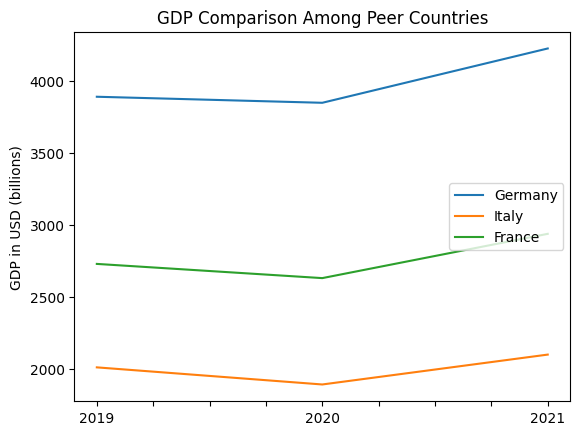

In [23]:
gdp_comparison_graph(comparable_countries)

In [24]:
#this prints growth rate
def printgdps(cns):
  for cn in cns:
    if cn == 'Norway, Svalbard and Jan Mayen':
      cn = 'Norway'
    print(cn)
    print(round(aagrate([x[1] for x in gdp_19to21_dict[cn]]),2))

printgdps(comparable_countries)

Germany
2.91
Italy
1.68
France
2.69


In [ ]:
''' OLD
def printgdps(cns):
  for cn in cns:
    print(round(aagrate([x[1] for x in gdp_13to18_dict[cn]]),2))

printgdps([ 'Viet Nam','Lao PDR','Cambodia', 'Thailand'])

SyntaxError: ignored

ECI Peer Comparison Graph

In [25]:
## UPDATED - MD
def eci_comparison_graph(cnames):
  fig, ax = plt.subplots()

  #cleanup country names 
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'France':
      country_name = 'France, Monaco'
      label = 'France'
    elif country_name == 'USA, Puerto Rico and US Virgin Islands':
      label = 'United States'
    else:
      label = country_name

    x_values = [int(x[0]) for x in eci_19to21_dict[country_name]]
    y_values = [x[1] for x in eci_19to21_dict[country_name]]
    
    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling
    ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])
    #print(eci_19to21_dict[country_name])

  plt.ylabel('ECI')  
  plt.legend()
  plt.title('ECI Comparison Among Peer Countries')
  plt.show()

<ipython-input-25-ace472259c0f>:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


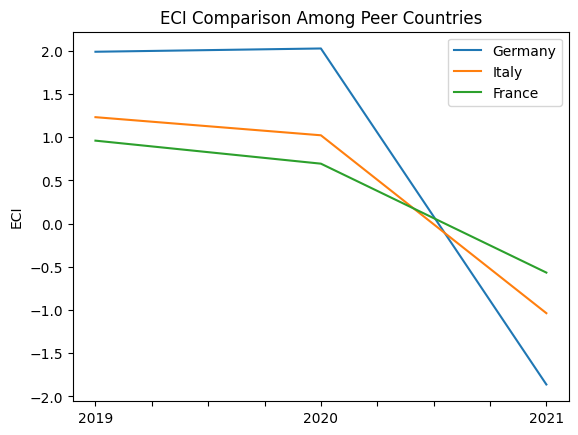

In [26]:
eci_comparison_graph(comparable_countries)

In [27]:
## UPDATED - MD:
def eci_change(cns):
  for country_name in cns:
    if country_name == 'France':
      country_name = 'France, Monaco'
    elif country_name == 'United States':
      country_name = 'USA, Puerto Rico and US Virgin Islands'
    elif country_name == 'Korea, Rep.':
      country_name = 'Republic of Korea'
    print(country_name)
    print(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2))

eci_change(comparable_countries)

Germany
-193.61
Italy
-184.16
France, Monaco
-159.05


GDP Growth and ECI Trend Graph

In [28]:
## ## UPDATED - MD:
def gdp_and_eci_graph(country_name):
  if country_name=='Vietnam': #not sure if some other names should be changed too 
    country_name='Viet Nam'
  elif country_name == 'France':
    country_name = 'France, Monaco'
  elif country_name == 'Norway, Svalbard and Jan Mayen':
    country_name_gdp = 'Norway'
  else:
    country_name_gdp = country_name
  

  fig, ax1 = plt.subplots()

  ax1.set_ylabel('GDP in USD (billions)')
  ax1.plot([x[0] for x in gdp_19to21_dict[country_name_gdp]],[float(x[1])/(10**9) for x in gdp_19to21_dict[country_name_gdp]], color = 'red', label='GDP')
  # Set the tick labels to custom values, '' added for consistent labeling
  ax1.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])
  ax1.legend(loc = 'center left')

  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')
  ax2.plot([x[0] for x in eci_19to21_dict[country_name]],[x[1] for x in eci_19to21_dict[country_name]], color = 'blue', label='ECI')
  ax2.legend(loc = 'center right')
  plt.title('GDP and ECI Trend for ' + country_name)
  plt.show()

<ipython-input-28-9f4493327c01>:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax1.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


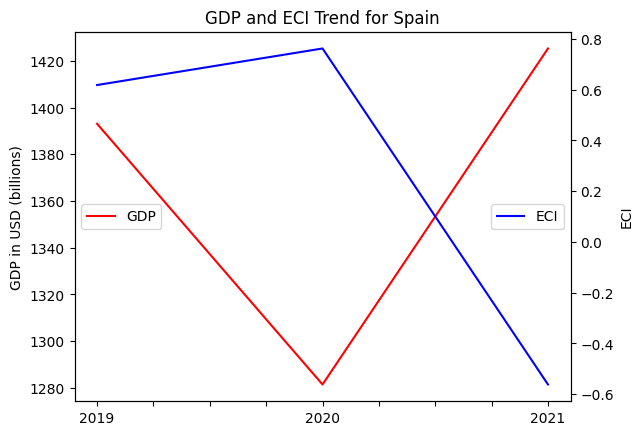

In [29]:
gdp_and_eci_graph(main_country)

In [ ]:
'''OLD
def gdp_and_eci_graph(country_name):
  fig, ax1 = plt.subplots()
  ax1.set_ylabel('GDP in USD (billions)')
  ax1.plot([x[0] for x in gdp_13to18_dict[country_name]],[float(x[1])/(10**9) for x in gdp_13to18_dict[country_name]], color = 'red', label='GDP')
  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')
  if country_name=='Vietnam':
    country_name='Viet Nam'
  ax2.plot([x[0] for x in eci_13to18_dict[country_name]],[x[1] for x in eci_13to18_dict[country_name]], color = 'blue', label='ECI')
  ax1.legend()
  ax2.legend()
  plt.title('GDP and ECI Trend for ' + country_name)
  plt.show()

# Proximity, Distance, and RID

Proximity

In [30]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [31]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [32]:
def compute_adi(df2,country_list,distance):
  raw_matrix = df2.to_numpy()
  matrix = [list(df2.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2 

In [33]:
# 18 is equivalent to year 2021
proximity = compute_proximity(mcp,product_sum)
proximity_18 = compute_proximity(mcp_18,product_sum_18)

distance = compute_distance(mcp,proximity)
adi, country_list2,product_list2  = compute_adi(df3,country_list,distance)

In [ ]:
#not used further, ignore 
#new_conts = [main_country,'Nigeria','Ukraine','Estonia','Canada','United Kingdom', 'Ireland', 'Sweden', 'Denmark', 'Israel', 'Lebanon', 'India', 'Pakistan', 'Chile', 'Kenya', 'Ghana', 'Qatar', 'Russian Federation', 'Norway, Svalbard and Jan Mayen','Viet Nam','Guatemala']

In [34]:
# UPDATED 
df_ = pd.DataFrame()
df_['Category'] = list(map(lambda x: x.replace('Precious Stones\t','Precious Stones'), product_list_18))
df_['RID'] = adi[main_country]
df_.sort_values(by="RID")

,Category,RID
4,Chemicals,-0.014399
12,Transportation,-0.013356
5,Chemical Manufacturing,-0.012094
6,Raw Manufacturing,-0.008101
11,Machinery and Construction,-0.007029
9,Textile,-0.000400
14,Daily Instruments,-0.000201
7,Wood Products,0.001143
10,Metals,0.001450
3,Energy Drilling and Mining,0.003908


In [35]:
# UPDATED - for multiple countries
df_comp = pd.DataFrame()
df_comp['Category'] = product_list_18
for count in comparable_countries:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = main_country + ' RID')

KeyError: ignored

In [ ]:
''' OLD
df_ = pd.DataFrame()
df_['Category'] = product_list_18
df_['RID'] = adi[new_conts[0]]
df_.sort_values(by="RID")

SyntaxError: ignored

# Sequential Strategy

Opportunity Gain

In [36]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [37]:
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)
    
  marginal = np.array(marginal)
  return marginal

In [38]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

#for i in range(len(country_list)):
#  print(country_list[i],opportunity_gain[i])

In [ ]:
# For computation of sequential strategies, refer to sequential strategy.py

In [ ]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [ ]:
# For computation of SOI, soi.ipynb

# SDV & SIDS

In [39]:
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    raw_matrix[19][3] = raw_matrix[19][3]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])
    
    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))
    
    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)
    
    print(product_list)
    print(country_list)

    mcp = []
    
    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)
    
    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))
    
    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)
    
    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)
    
    #compute PCI
    mpp = np.array(mpp)
    
    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)
    
    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])
    
    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))
    
    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)
    
    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)
    
    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)
        
    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)
    
    
    #computing sequential strategy
    strategy = []
    
    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    print("Before Iteration: ")
    for i in range(0,len(marginal[country_index])):
        print(product_list[i], ": ", marginal[country_index][i])
    print(" ")
    
    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)
    
    ite_round = 0
    prev_industry = []
    
    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1
        
        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)
        
        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export
    
        print("increase ", industry, " in ", country, " by ", export_increase, " USD")
    
        raw_matrix[country_index+1][industry_index+1] = required_export*1.3
        
        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))
    
        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)
    
        mcp = []
     
        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)
    
        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))
    
        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)
    
        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)
    
        #compute PCI
        mpp = np.array(mpp)
    
        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)
    
        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])
    
        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))
    
        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)
    
        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)
    
        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)
        
        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)
        
        print("Iteration ", ite_round, ": ")
        for i in range(0,len(marginal[country_index])):
            print(product_list[i], ": ", marginal[country_index][i])
        print(" ")
        
        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)
    
    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')
    
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    print(f'{country} completed')
    
    
## UPDATED - MD:  from here only 
# TO DO: update "comparable_countries" below if needed
def main():
    countries = comparable_countries

    for country in countries:
      if country == 'France':
        country = 'France, Monaco'
      elif country == 'United States':
        country = 'USA, Puerto Rico and US Virgin Islands'
      sdv_and_sids(country, root_path+'2019-2021 cleaned/2021clean')

In [40]:
if __name__ == "__main__":
    main()   #Optional: Change the countries and year above to have different results

<ipython-input-39-182534a769d0>:33: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['China', 'Angola', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Canada', 'Cayman Islands', 'Chile', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopi

Greedy Algorithm

In [41]:
## UPDATED - MD:
# run this - didn't work w/o resetting it 
root_path = 'drive/My Drive/ECI/ECI Research/Fall 2022/Data/'

In [42]:
## TO DO: Updated path

def greedy(country, year, percentage, num_part):

    df = pd.read_csv(root_path + '2019-2021 cleaned/2021clean.csv')
    raw_matrix = df.to_numpy()
    matrix = [list(df.columns)]

    for row in raw_matrix:
      if np.min(row[1::]) > 0:
        matrix.append(list(row))
    
    print(len(raw_matrix))
    product_list = matrix[0][1::]
    print(product_list)
    country_list = []
    for i in range(1,len(matrix)):
        country_list.append(matrix[i][0])
        if country in matrix[i][0]:
           country_index = i
           #print(country_index)
           total_export = np.sum(matrix[i][1::])
    
    budget = (percentage/100) * total_export
    print(f'Original total export is {total_export}, budget is {budget}')
    mcp = compute_mcp(matrix)[2]
    mcc = compute_mcc(mcp)
    last_eci = compute_eci(mcc)[country_index-1]
    print(f'ECI this year is {last_eci}')
    each_amount = budget/num_part
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    while total < budget:
        eci = []
        print(f'Progress: {round(total/budget, 2)}')
        for i in tqdm(range(1, len(matrix[0]))):
            matrix[country_index][i] += each_amount
            mcp = compute_mcp(matrix)[2]
            mcc = compute_mcc(mcp)
            eci.append(compute_eci(mcc)[country_index - 1])
            matrix[country_index][i] -= each_amount
        if  eci.count(max(eci)) != 1:
            #print('path 2')
            multiple = 2
            total_temp = total
            temp_each = multiple*each_amount
            while max(eci)<=last_eci and total_temp < budget:
                temp_each = multiple*each_amount
                print(f'Multiple = {multiple}, Raise each amount to {temp_each}')
                eci = []
                for i in tqdm(range(1, len(matrix[0]))):
                    matrix[country_index][i] += temp_each
                    mcp = compute_mcp(matrix)[2]
                    mcc = compute_mcc(mcp)
                    eci.append(compute_eci(mcc)[country_index - 1])
                    matrix[country_index][i] -= temp_each
                multiple += 1
                total_temp = total + temp_each
            if max(eci)<=last_eci and total_temp == budget:
               print('ECI does not change any more, add to the most adjacent ')
               export_increase = []
               mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
               total_sum = np.sum(product_sum)
               for j in range(0,len(mcp[0])):
                  if mcp[country_index-1][j] == 1:
                      export_increase.append(0)
                  else:
                      export = raw_matrix[country_index][j+1]
                      country_export = country_sum[country_index-1]
                      product_export = product_sum[j]
                      export_increase.append((product_export*country_export/total_sum)-export)
               country_dist = np.array(export_increase)
               min_distance = np.where(country_dist > 0, country_dist, np.inf).argmin()
               matrix[country_index][min_distance + 1] += temp_each
            else:
               matrix[country_index][np.argmax(eci) + 1] += temp_each
               print(eci)
               print(f'After increasing, largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
               print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            total = total_temp
            last_eci = max(eci)
        else:
            #print('path 3')
            largest_component = np.argmax(eci) + 1
            print(eci)
            print(f'largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
            print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            last_eci = max(eci)
            matrix[country_index][np.argmax(eci) + 1] += each_amount
            total += each_amount
    optimal_vector = np.array(matrix[country_index][1::]) - original_vector
    max_eci = last_eci
    return dict(zip(product_list,optimal_vector)), max_eci

In [43]:
## UPDATED - MD:
## this one takes some time to run 
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for percentages of 5%, 10%, 15%, 20%
# CHECK THE YEAR
greedy(main_country, 2021, 10, 12)

137
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
Original total export is 505016718644.0, budget is 50501671864.4
ECI this year is -0.5616917471435152
Progress: 0.0


100%|██████████| 18/18 [00:16<00:00,  1.10it/s]


[-0.5660058585812666, -0.5616917471435152, -0.5616917471435152, -0.5616917471435152, -0.5616917471435152, -0.5616917471435152, -0.5616917471435152, -0.5305623837673169, -0.5616917471435152, -0.5023958483760858, -0.5616917471435152, -0.5573929408805521, -0.5616917471435152, -0.5444009299584697, -0.5616917471435152, -0.5616917471435152, -0.5616917471435152, -0.5616917471435152]
largest argument is 10, product is Textile
last_eci is -0.5616917471435152, this_eci is -0.5023958483760858
Progress: 0.08


100%|██████████| 18/18 [00:15<00:00,  1.19it/s]


[-0.5059044921705416, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858, -0.4790128458374909, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858, -0.4978396250053628, -0.5023958483760858, -0.4919986159185416, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858, -0.5023958483760858]
largest argument is 8, product is Wood Products
last_eci is -0.5023958483760858, this_eci is -0.4790128458374909
Progress: 0.17


...

100%|██████████| 18/18 [00:15<00:00,  1.19it/s]


Multiple = 2, Raise each amount to 8416945310.733334


100%|██████████| 18/18 [00:15<00:00,  1.19it/s]

[-0.10548983353010066, -0.10236958741264349, -0.10236958741264349, -0.10236958741264349, -0.25883221359769526, -0.10236958741264349, -0.10236958741264349, -0.10236958741264349, -0.10236958741264349, -0.10236958741264349, -0.10236958741264349, -0.126397165612512, -0.10236958741264349, -0.15893432985973233, -0.10236958741264349, -0.10236958741264349, -0.3560721346169488, -0.10236958741264349]
After increasing, largest argument is 2, product is Vegetables, Fruits and Plants
last_eci is -0.10236958741264349, this_eci is -0.10236958741264349


({'Animals and By-products': 0.0,
  'Vegetables, Fruits and Plants': 8416945310.733334,
  'Food and Preparations': 0.0,
  'Energy Drilling and Mining': 3.814697265625e-06,
  'Chemicals': -1.9073486328125e-06,
  'Chemical Manufacturing': 4208472655.3666687,
  'Raw Manufacturing': 3.814697265625e-06,
  'Wood Products': 4208472655.366665,
  'Clothing and Accessories': 0.0,
  'Textile': 21042363276.833336,
  'Metals': 3.814697265625e-06,
  'Machinery and Construction': 4208472655.366667,
  'Transportation': 0.0,
  'Weapons': 8416945310.7333355,
  'Daily Instruments': 3.814697265625e-06,
  'Precious Stones\t': -1.9073486328125e-06,
  'High-complexity Products': 0.0,
  'Services and Utilities': 0.0},
 -0.10236958741264349)

In [ ]:
'''OLD
greedy('Viet Nam', 2018, 10, 12)

SyntaxError: ignored

# SOI

In [44]:
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

In [45]:
zzz+=1
def compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    plt.scatter(independent, dependent)
                    plt.show()
                    print(model.cov_HC0)
                    print(country_list[i], "!!!")
                    print(country_list2[j], "???")
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
                 
    matrix = open(root_path+'structual optimality index adi ("+str(zzz)+ ").csv','w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [46]:
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH        
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [47]:
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
 #TO FIX PATH                            
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [48]:
# TO FIX years 
def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(country_list, country_list2)
    independent = []
    dependent = []
    name = []
    common2= []
    growth={}
    for i in common:

      #old
        #if i in gdp_raw.index.values and gdp_raw['2013'][i] != 0:
            #pct_change=(float(gdp_raw['2018'][i])-float(gdp_raw['2013'][i]))/float(gdp_raw['2013'][i])

         if i in gdp_raw.index.values and gdp_raw['2019'][i] != 0:
            pct_change=(float(gdp_raw['2021'][i])-float(gdp_raw['2019'][i]))/float(gdp_raw['2019'][i])   
            dependent.append(pct_change)
            independent.append(soi[i])
            growth[i]=pct_change
            common2.append(i)
    # plt.scatter(independent,dependent)
    # plt.title('SOI v GDP Growth')
    # plt.xlabel('SOI')
    # plt.ylabel('% Change in GDP')
    # plt.show()
    
    # print(np.setdiff1d(common,common2))
    # print()
    # print(common)
    # print()
    # print(common2)
  
    dfs=  pd.DataFrame({'Country': common2,'GDP':dependent, 'SOI': independent})
    #dfs.set_index('Country', inplace=True)
    model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()


    fig = px.scatter(dfs, x="SOI", y="GDP",  text='Country', trendline="ols") 
    fig.update_layout(
    title="Regression of GDP over SOI",
    yaxis_title="% Growth in GDP 2019-2021", #fixed years
    xaxis_title="SOI",
    height=600,
    width=900,
    title_x=.5,
    font=dict(
        family="Times New Roman",
        size=15
        ) )
    #fig.update_traces(textposition='top center')
    fig.show()
    fig2 = plt.figure(figsize=(12,8))
    fig2 = sm.graphics.plot_regress_exog(model,'SOI', fig=fig2)
    fig3, ax = plt.subplots(figsize=(12,8))
    fig3 = sm.graphics.influence_plot(model, ax=ax, criterion='Cooks')
    return model, growth

In [49]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)


In [50]:

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    # print(independent)
                    # print(dependent)
                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="RID"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)

                    correlation_matrix = np.corrcoef(dependent, independent)
                    correlation_xy = correlation_matrix[0,1]
                    r_squared = correlation_xy**2
                    print("ASDFASDFASDFSADFASDFASDFASDF R^2: ", r_squared, "ASDFASDFASDFASDF)\n\n\n")
                    fig.show()
                        
                      

SOI w/ ADI

categorization verified


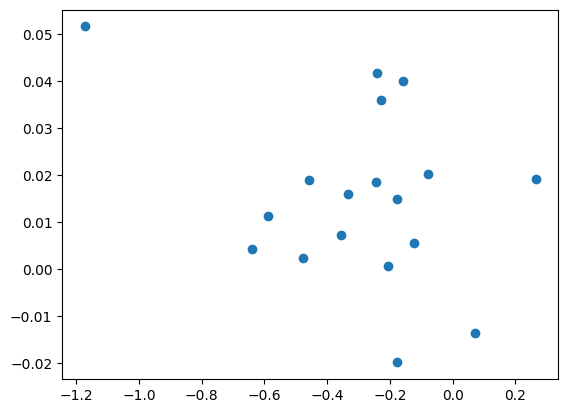

[[3.52510110e-05 6.01204470e-05]
 [6.01204470e-05 1.86455987e-04]]
China !!!
China ???


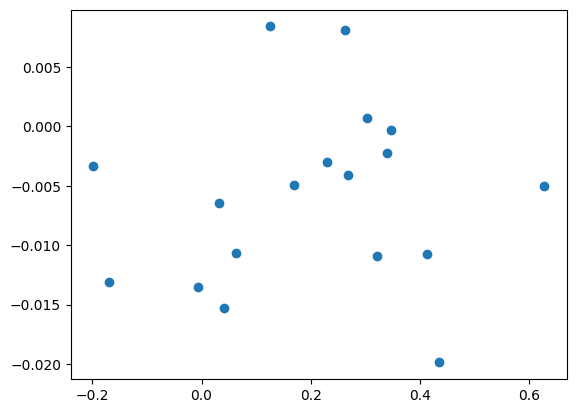

[[ 4.19625241e-06 -7.84594853e-06]
 [-7.84594853e-06  4.77667207e-05]]
Angola !!!
Angola ???


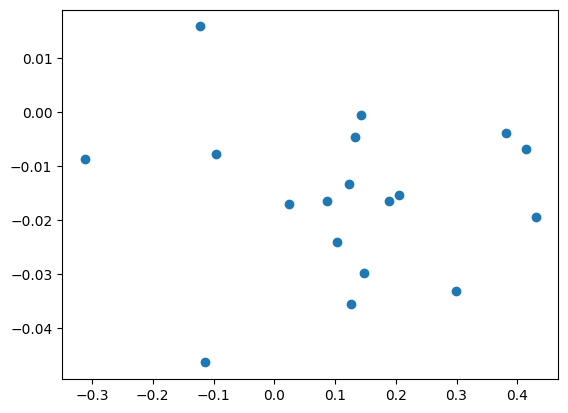

[[ 2.29312518e-05 -6.99201226e-05]
 [-6.99201226e-05  3.42998706e-04]]
Argentina !!!
Argentina ???


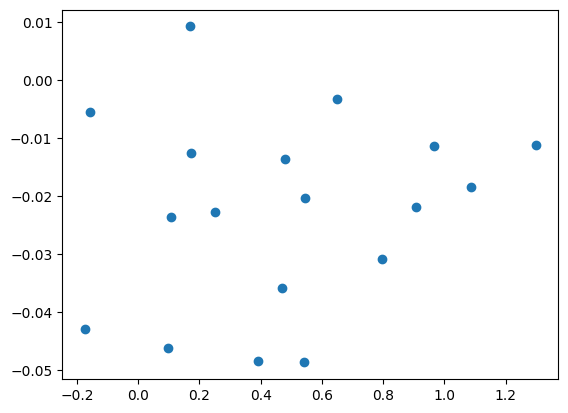

[[ 4.39768508e-05 -4.61673796e-05]
 [-4.61673796e-05  6.25734531e-05]]
Armenia !!!
Armenia ???


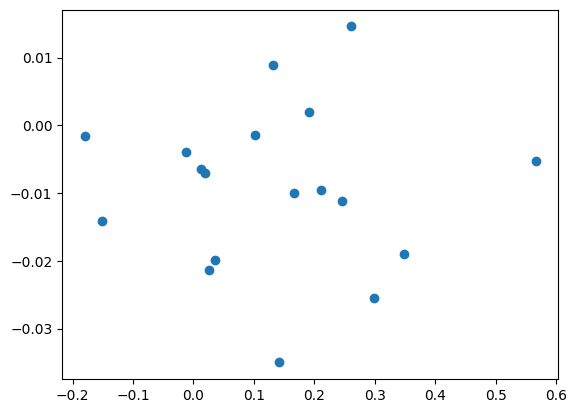

[[ 7.28231853e-06 -6.04405903e-06]
 [-6.04405903e-06  1.16729681e-04]]
Aruba !!!
Aruba ???


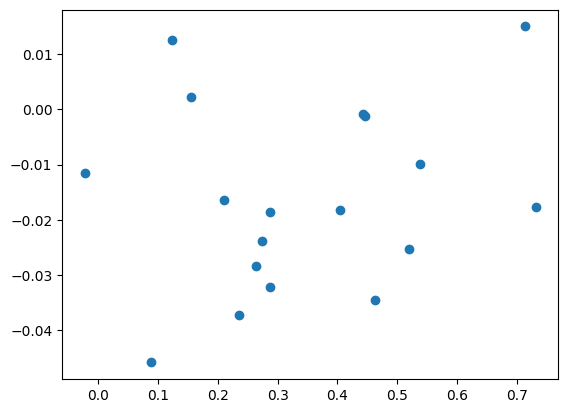

[[ 7.95062977e-05 -1.73479131e-04]
 [-1.73479131e-04  4.58203546e-04]]
Australia !!!
Australia ???


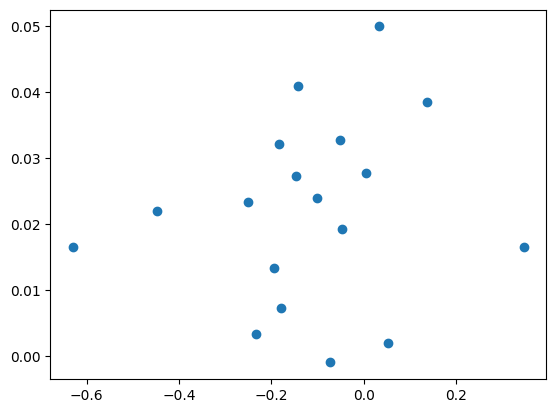

[[1.57381033e-05 3.14317823e-05]
 [3.14317823e-05 1.21178505e-04]]
Austria !!!
Austria ???


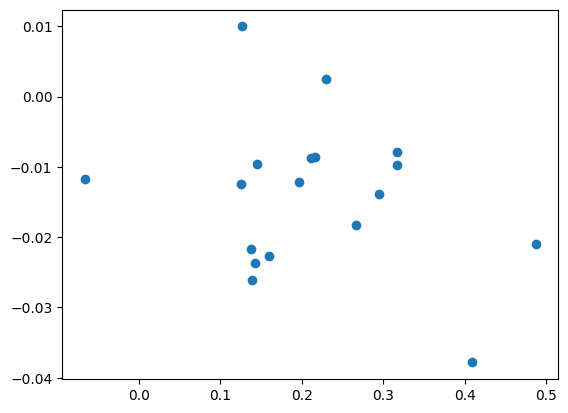

[[ 2.05545483e-05 -7.06394749e-05]
 [-7.06394749e-05  3.36763917e-04]]
Azerbaijan !!!
Azerbaijan ???


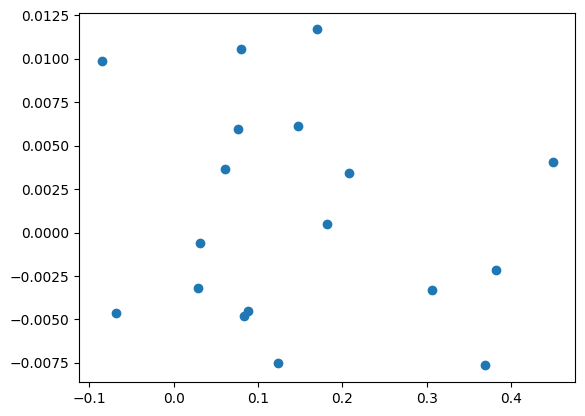

[[ 4.36382038e-06 -1.42572369e-05]
 [-1.42572369e-05  8.22998805e-05]]
Barbados !!!
Barbados ???


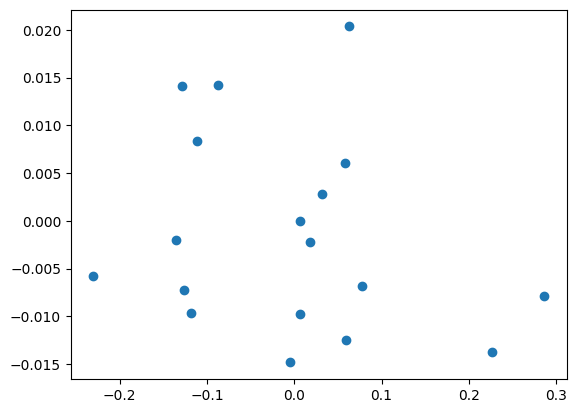

[[ 5.35879355e-06 -1.79157992e-06]
 [-1.79157992e-06  2.10914896e-04]]
Belarus !!!
Belarus ???


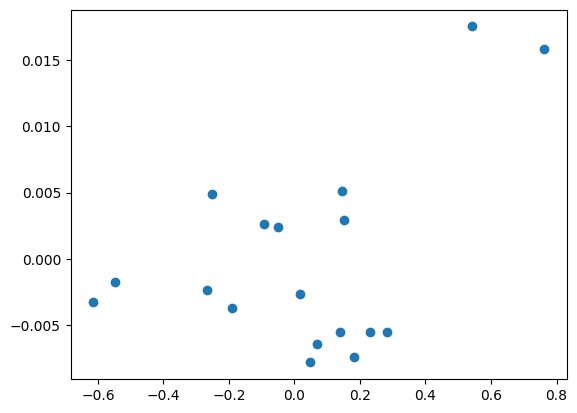

[[1.98617446e-06 3.23206146e-06]
 [3.23206146e-06 2.69999020e-05]]
Belgium !!!
Belgium ???


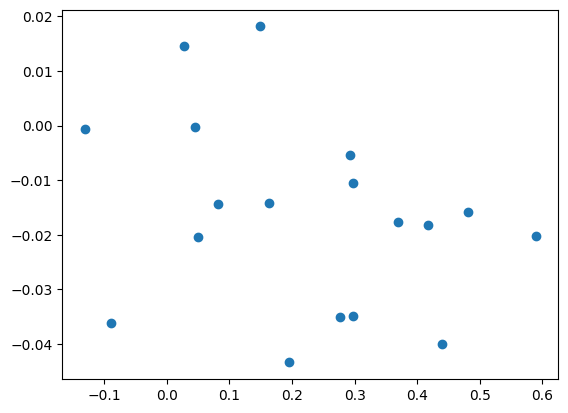

[[ 4.26476987e-05 -9.81704963e-05]
 [-9.81704963e-05  3.13754189e-04]]
Belize !!!
Belize ???


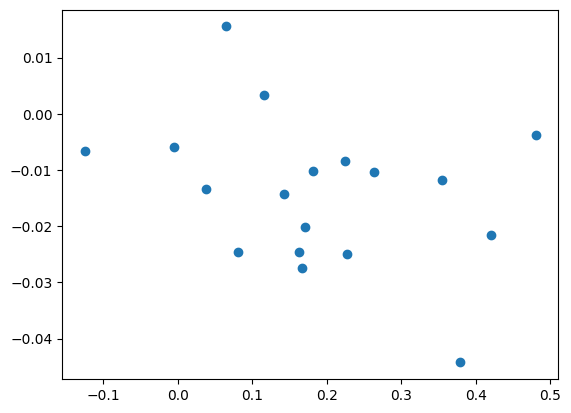

[[ 1.71760237e-05 -6.26140473e-05]
 [-6.26140473e-05  4.16774021e-04]]
Benin !!!
Benin ???


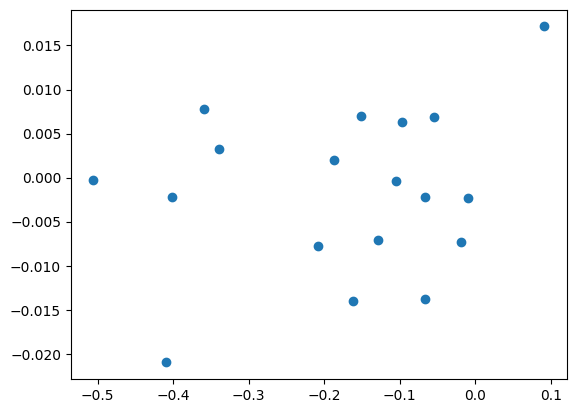

[[1.13189440e-05 3.97245893e-05]
 [3.97245893e-05 2.24396417e-04]]
Bermuda !!!
Bermuda ???


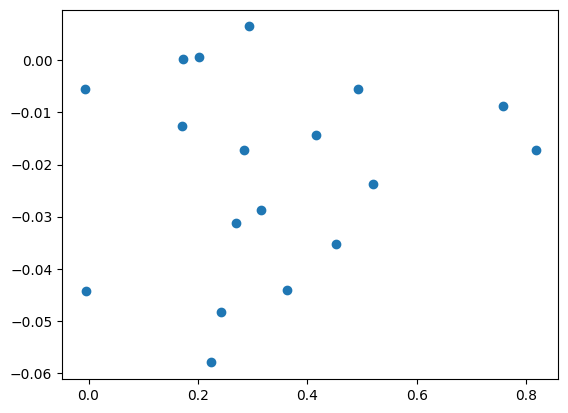

[[ 6.83845805e-05 -1.13718412e-04]
 [-1.13718412e-04  2.30343409e-04]]
Plurinational State of Bolivia !!!
Plurinational State of Bolivia ???


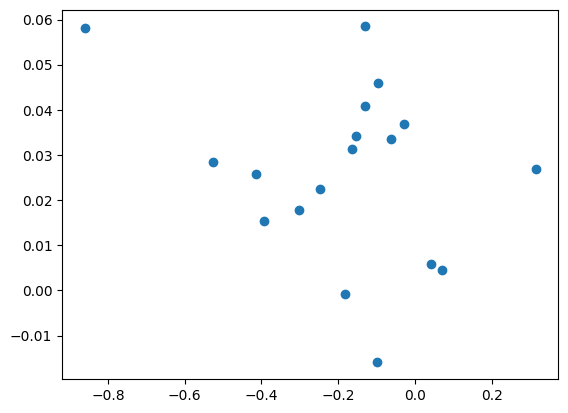

[[2.94984275e-05 4.76229546e-05]
 [4.76229546e-05 1.92171644e-04]]
Bosnia Herzegovina !!!
Bosnia Herzegovina ???


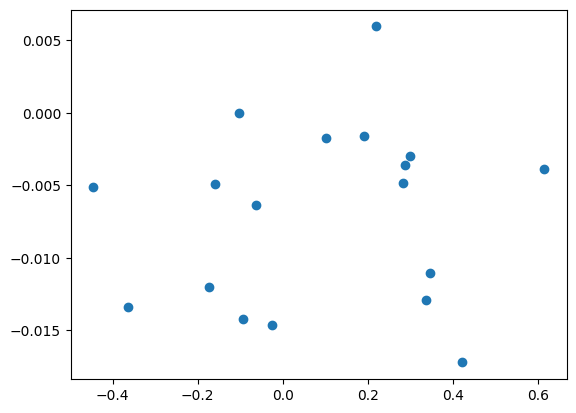

[[ 1.91202284e-06 -4.18044586e-07]
 [-4.18044586e-07  1.91431809e-05]]
Botswana !!!
Botswana ???


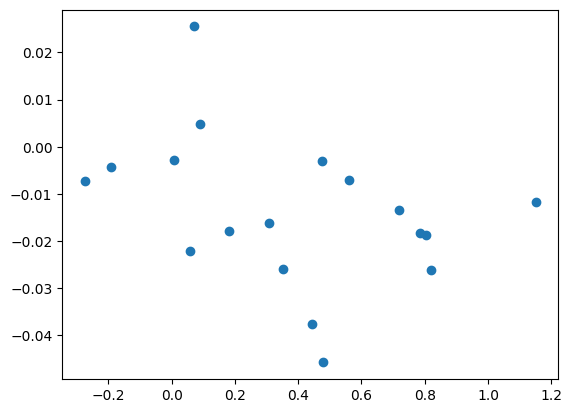

[[ 2.16294912e-05 -2.18669436e-05]
 [-2.18669436e-05  4.60350815e-05]]
Brazil !!!
Brazil ???


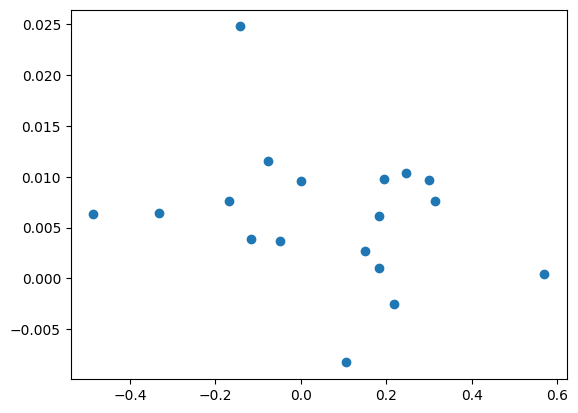

[[ 2.58344022e-06 -3.04486691e-06]
 [-3.04486691e-06  2.04989234e-05]]
Brunei Darussalam !!!
Brunei Darussalam ???


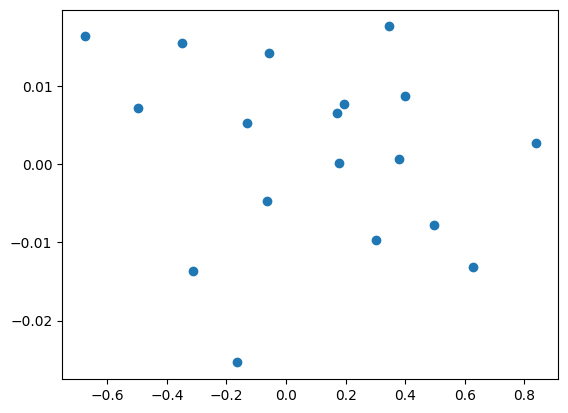

[[ 8.49553786e-06 -8.83693058e-06]
 [-8.83693058e-06  3.83717714e-05]]
Bulgaria !!!
Bulgaria ???


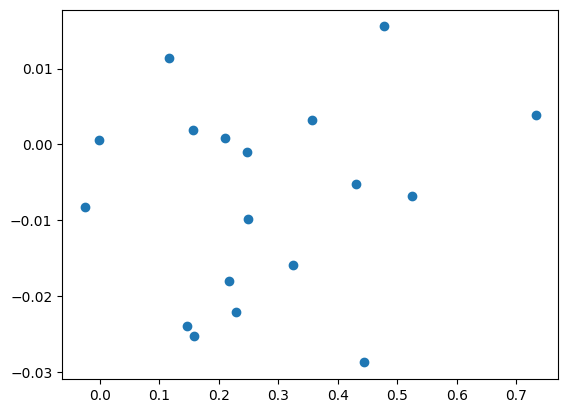

[[ 2.25000297e-05 -5.10520420e-05]
 [-5.10520420e-05  1.87140096e-04]]
Burundi !!!
Burundi ???


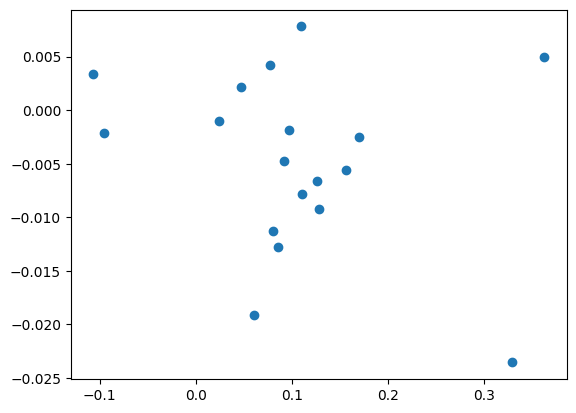

[[ 4.77914479e-06 -3.40236754e-05]
 [-3.40236754e-05  5.32847196e-04]]
Cambodia !!!
Cambodia ???


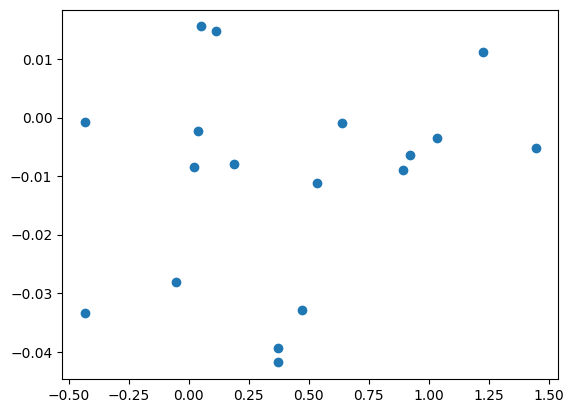

[[ 3.00494549e-05 -2.43825087e-05]
 [-2.43825087e-05  3.40367361e-05]]
Canada !!!
Canada ???


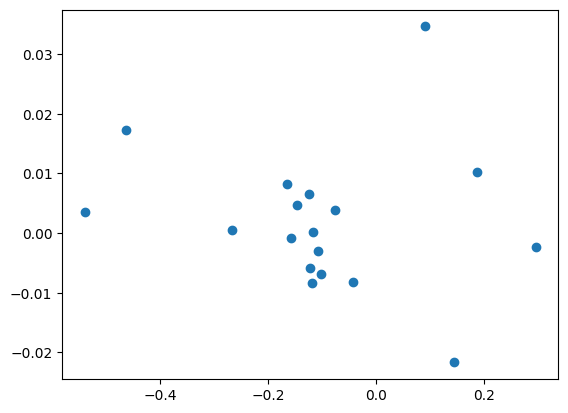

[[1.45039905e-05 4.59815846e-05]
 [4.59815846e-05 2.08776499e-04]]
Cayman Islands !!!
Cayman Islands ???


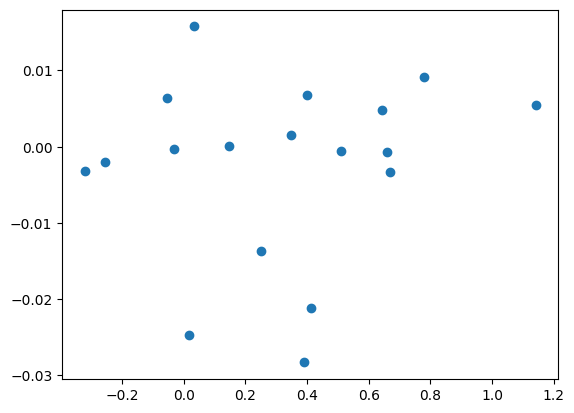

[[ 1.15878843e-05 -1.02844004e-05]
 [-1.02844004e-05  2.27531758e-05]]
Chile !!!
Chile ???


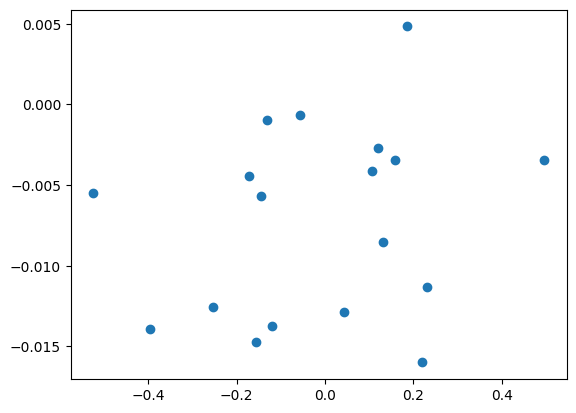

[[1.79595574e-06 1.35530952e-06]
 [1.35530952e-06 2.24204932e-05]]
China, Hong Kong Special Administrative Region !!!
China, Hong Kong Special Administrative Region ???


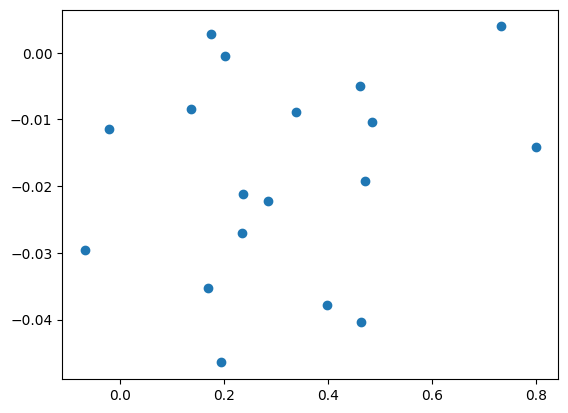

[[ 2.99656578e-05 -5.41330344e-05]
 [-5.41330344e-05  1.58761717e-04]]
Colombia !!!
Colombia ???


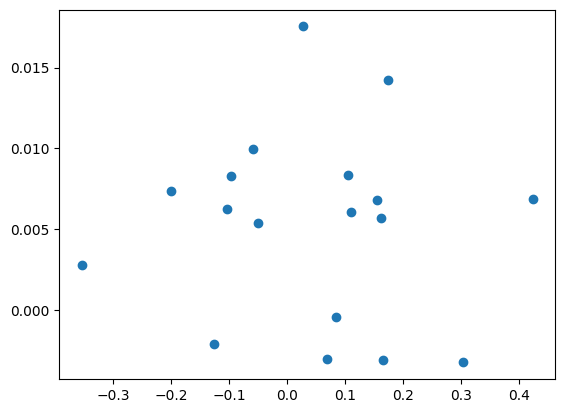

[[1.69510847e-06 5.90424422e-07]
 [5.90424422e-07 3.31449378e-05]]
Congo !!!
Congo ???


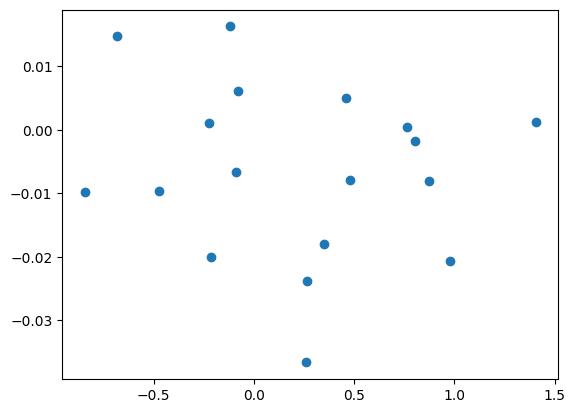

[[ 1.15671738e-05 -6.45870416e-06]
 [-6.45870416e-06  1.93414593e-05]]
Croatia !!!
Croatia ???


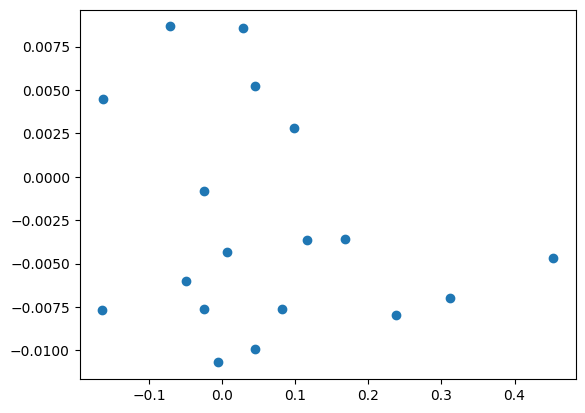

[[ 2.72292678e-06 -8.01147339e-06]
 [-8.01147339e-06  4.40877170e-05]]
Cyprus !!!
Cyprus ???


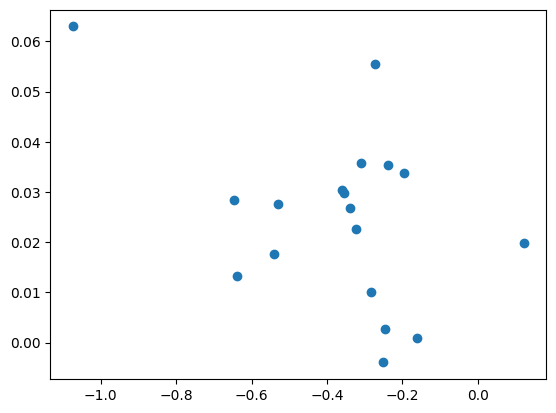

[[4.47288637e-05 8.26141802e-05]
 [8.26141802e-05 2.13371256e-04]]
Czechia !!!
Czechia ???


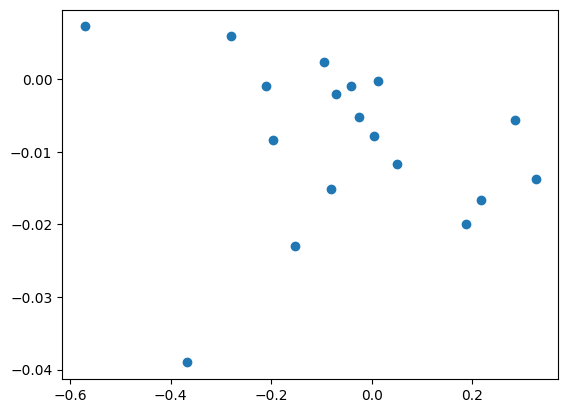

[[ 4.37695405e-06 -1.51022067e-05]
 [-1.51022067e-05  2.11203316e-04]]
Denmark !!!
Denmark ???


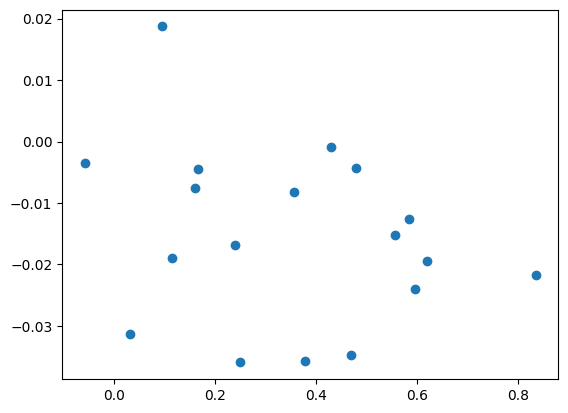

[[ 4.11253260e-05 -6.83918464e-05]
 [-6.83918464e-05  1.37734527e-04]]
Ecuador !!!
Ecuador ???


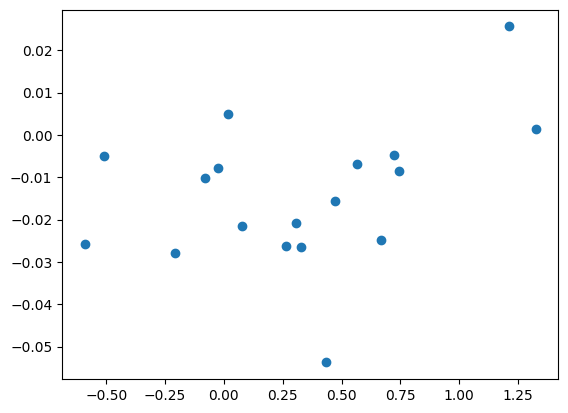

[[ 1.44198646e-05 -1.01161810e-05]
 [-1.01161810e-05  5.14227727e-05]]
Egypt !!!
Egypt ???


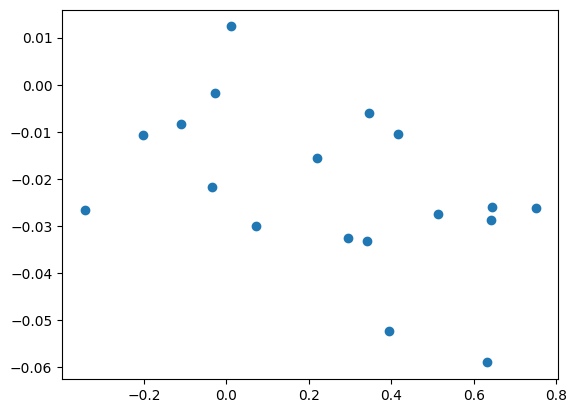

[[ 1.95493499e-05 -2.90061040e-05]
 [-2.90061040e-05  1.14296046e-04]]
El Salvador !!!
El Salvador ???


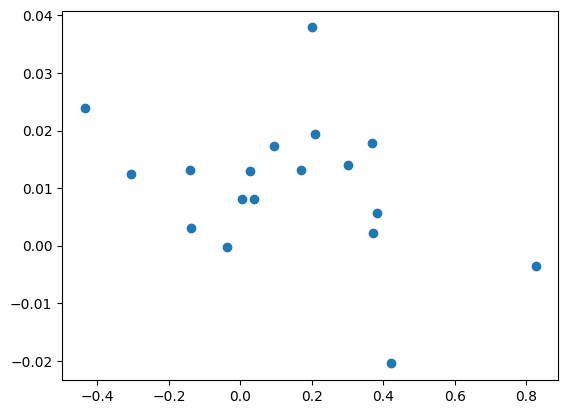

[[5.53041782e-06 2.30597179e-06]
 [2.30597179e-06 4.63936340e-05]]
Estonia !!!
Estonia ???


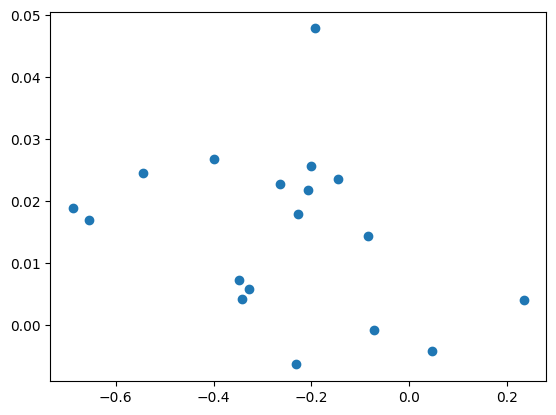

[[1.71390796e-05 2.36173251e-05]
 [2.36173251e-05 5.69296325e-05]]
EU-28 !!!
EU-28 ???


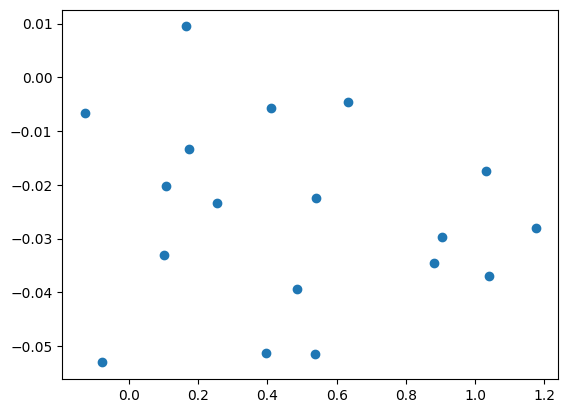

[[ 5.33411991e-05 -5.90733141e-05]
 [-5.90733141e-05  8.32819174e-05]]
Fiji !!!
Fiji ???


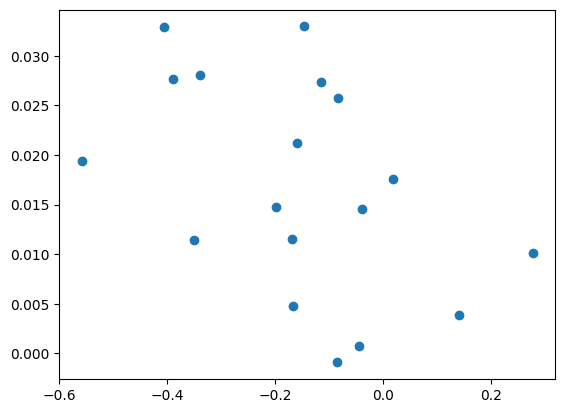

[[6.26749572e-06 9.90125985e-06]
 [9.90125985e-06 6.69336033e-05]]
Finland !!!
Finland ???


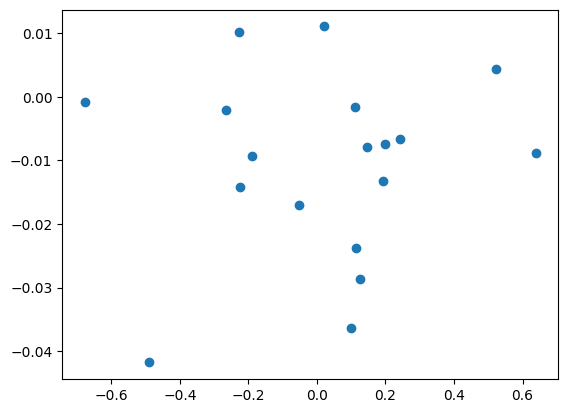

[[ 1.15121547e-05 -1.66589493e-05]
 [-1.66589493e-05  1.19468496e-04]]
France, Monaco !!!
France, Monaco ???


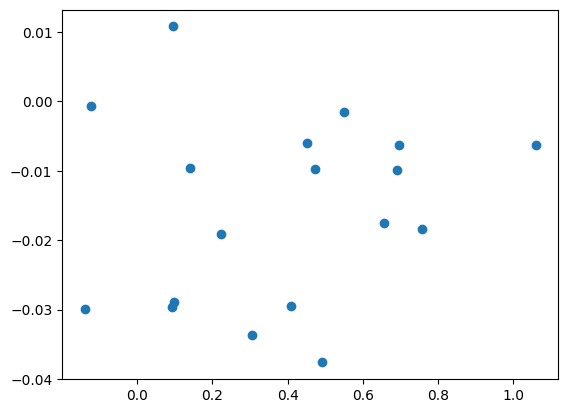

[[ 3.13881918e-05 -4.37249732e-05]
 [-4.37249732e-05  7.85748674e-05]]
Georgia !!!
Georgia ???


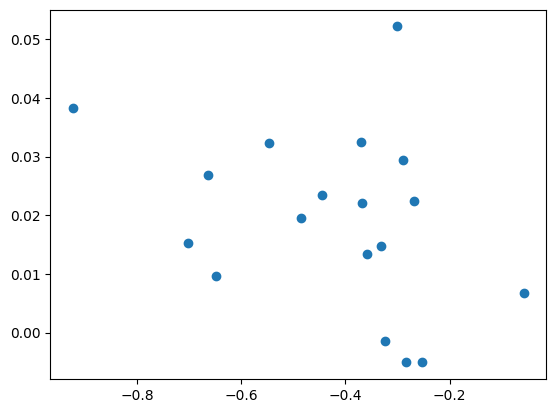

[[5.53663560e-05 8.62262601e-05]
 [8.62262601e-05 1.58170824e-04]]
Germany !!!
Germany ???


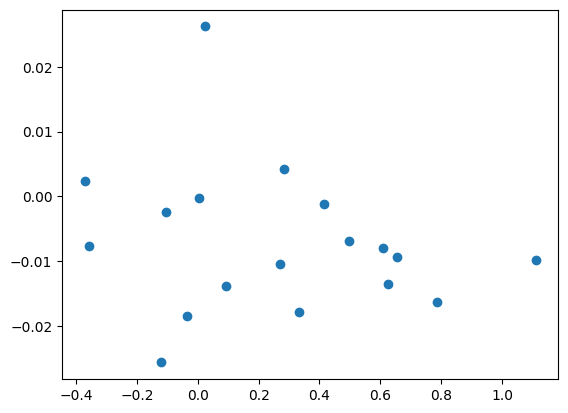

[[ 1.29568941e-05 -1.52021704e-05]
 [-1.52021704e-05  2.29671694e-05]]
Greece !!!
Greece ???


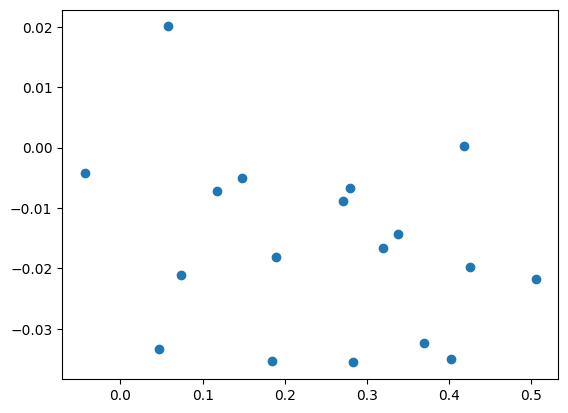

[[ 5.27196270e-05 -1.47090413e-04]
 [-1.47090413e-04  5.01210369e-04]]
Grenada !!!
Grenada ???


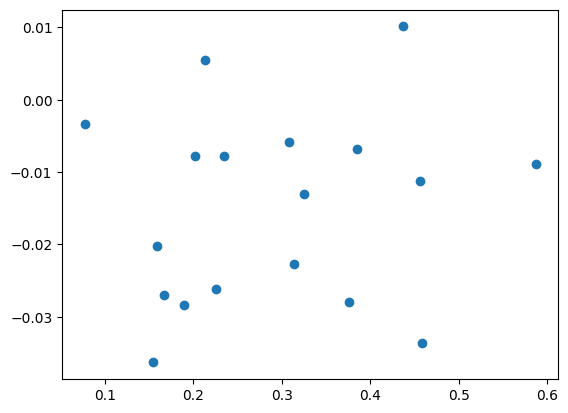

[[ 5.45506543e-05 -1.54141477e-04]
 [-1.54141477e-04  5.22161096e-04]]
Guyana !!!
Guyana ???


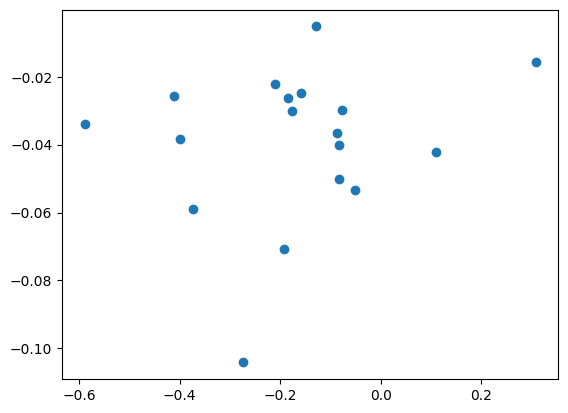

[[2.32934861e-05 2.18880476e-05]
 [2.18880476e-05 3.47794269e-04]]
Hungary !!!
Hungary ???


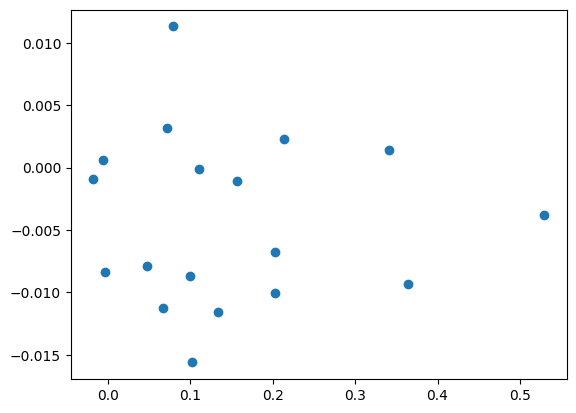

[[ 4.87532256e-06 -1.22128333e-05]
 [-1.22128333e-05  5.33210794e-05]]
Iceland !!!
Iceland ???


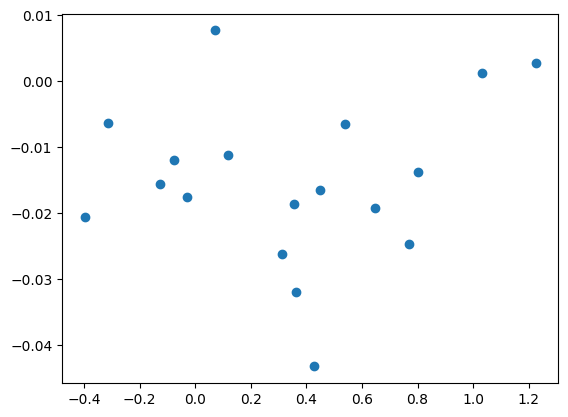

[[ 9.60950646e-06 -8.09340380e-06]
 [-8.09340380e-06  3.36163476e-05]]
India !!!
India ???


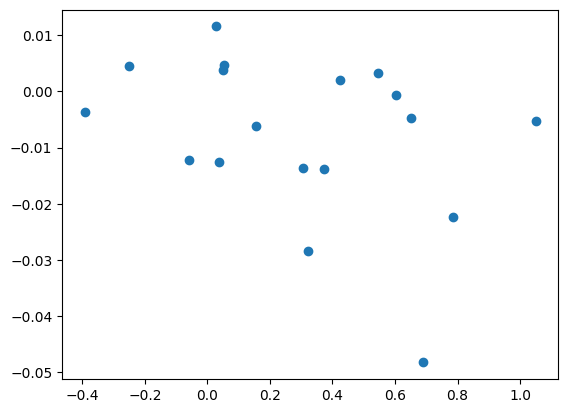

[[ 7.28873805e-06 -6.21652200e-06]
 [-6.21652200e-06  6.60569605e-05]]
Indonesia !!!
Indonesia ???


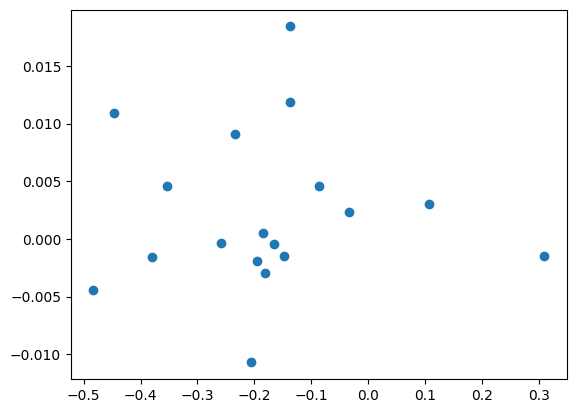

[[3.00661404e-06 5.07399424e-06]
 [5.07399424e-06 4.04726248e-05]]
Ireland !!!
Ireland ???


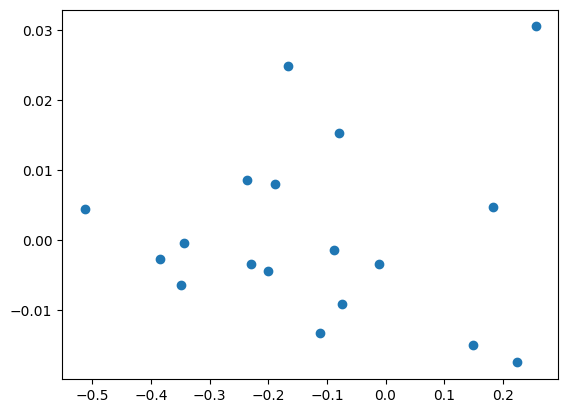

[[2.08031805e-05 6.78582787e-05]
 [6.78582787e-05 2.94662471e-04]]
Israel !!!
Israel ???


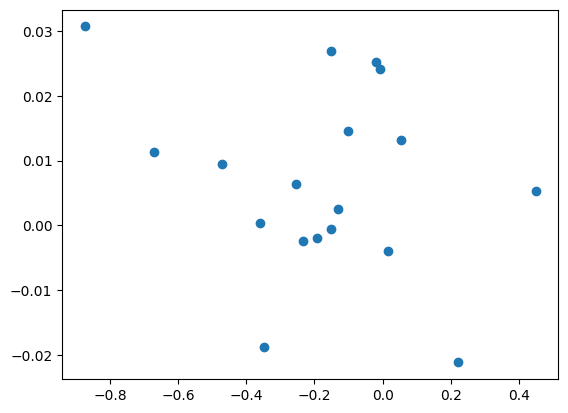

[[1.50214430e-05 2.27951913e-05]
 [2.27951913e-05 1.06659453e-04]]
Italy !!!
Italy ???


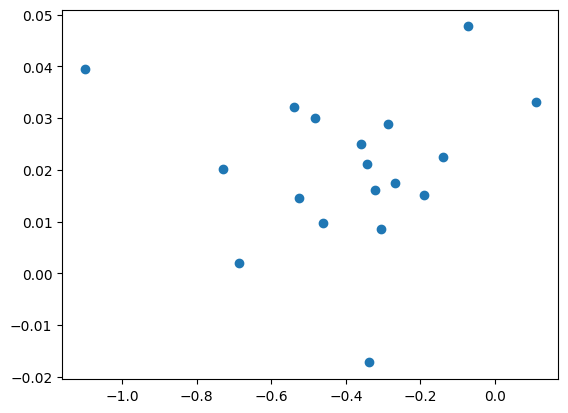

[[4.49599945e-05 8.76442274e-05]
 [8.76442274e-05 2.28692918e-04]]
Japan !!!
Japan ???


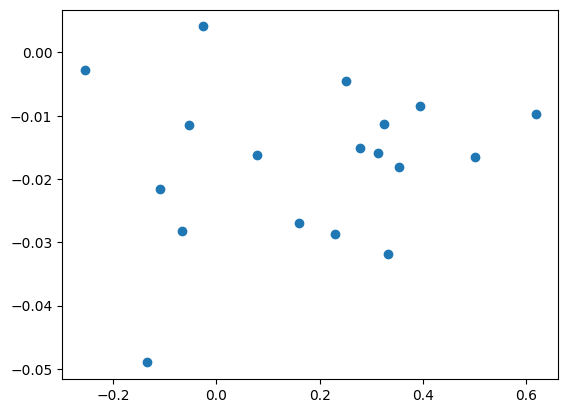

[[ 2.32034362e-05 -5.99252954e-05]
 [-5.99252954e-05  1.90930665e-04]]
Jordan !!!
Jordan ???


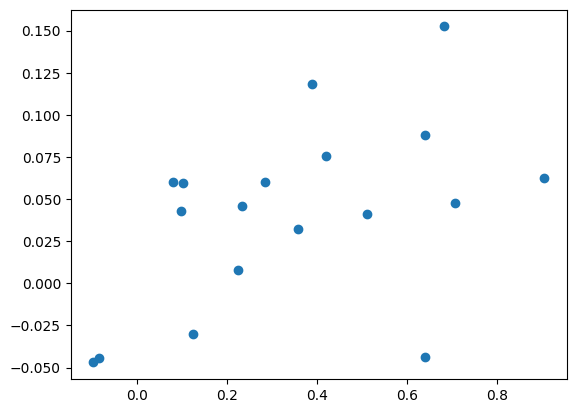

[[ 0.0002373  -0.00046422]
 [-0.00046422  0.00173144]]
Kenya !!!
Kenya ???


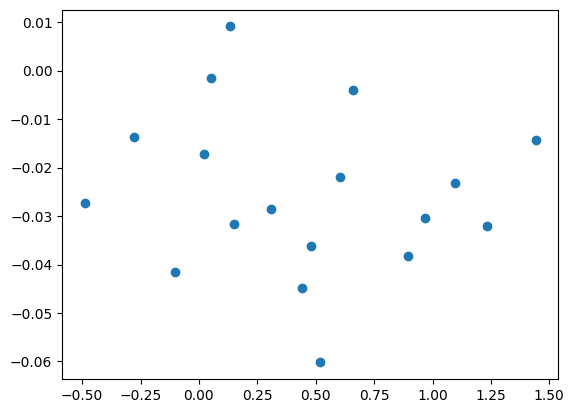

[[ 2.44710661e-05 -1.73274036e-05]
 [-1.73274036e-05  2.87075471e-05]]
Kyrgyzstan !!!
Kyrgyzstan ???


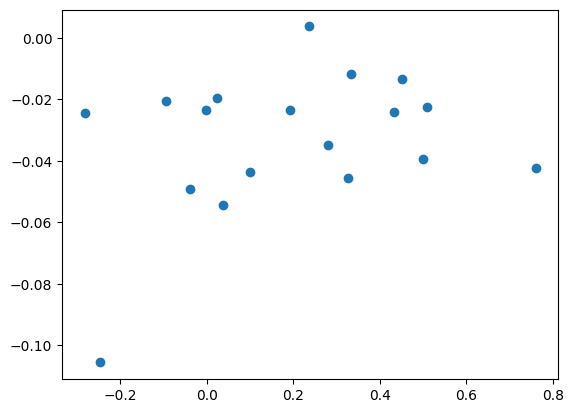

[[ 7.60342780e-05 -1.88335440e-04]
 [-1.88335440e-04  6.22927705e-04]]
Latvia !!!
Latvia ???


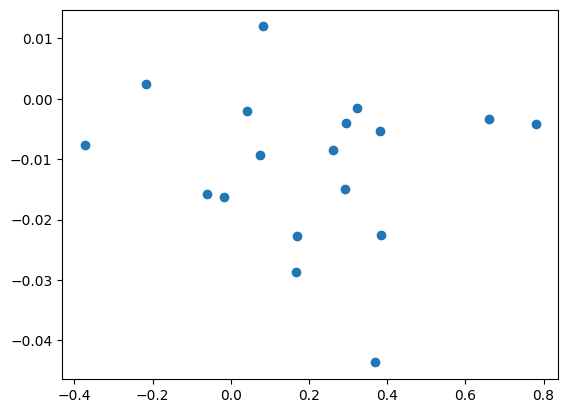

[[ 8.70613292e-06 -6.99502931e-06]
 [-6.99502931e-06  6.63029473e-05]]
Lebanon !!!
Lebanon ???


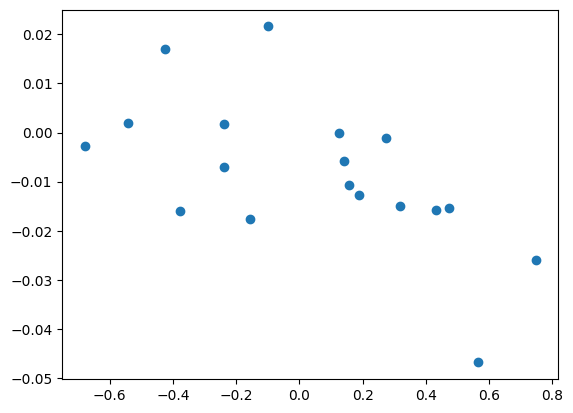

[[ 8.09301586e-06 -2.51184881e-06]
 [-2.51184881e-06  5.11496729e-05]]
Lithuania !!!
Lithuania ???


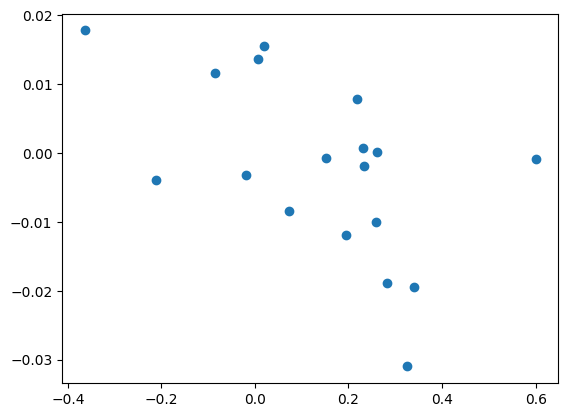

[[ 6.50573375e-06 -1.20107335e-05]
 [-1.20107335e-05  1.58853755e-04]]
Luxembourg !!!
Luxembourg ???


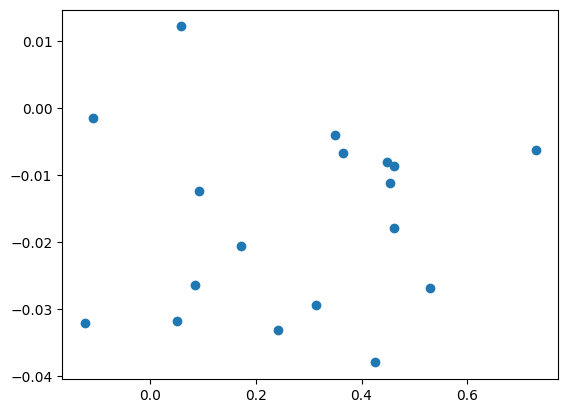

[[ 3.41000546e-05 -7.13437116e-05]
 [-7.13437116e-05  1.98467696e-04]]
Madagascar !!!
Madagascar ???


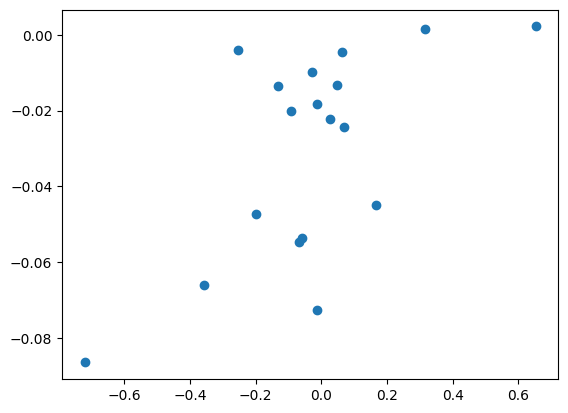

[[ 2.28501918e-05 -8.42473234e-06]
 [-8.42473234e-06  1.62986001e-04]]
Malaysia !!!
Malaysia ???


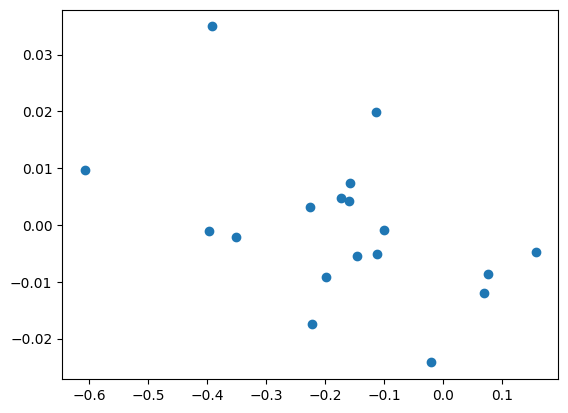

[[8.73130448e-06 1.92352638e-05]
 [1.92352638e-05 1.82975761e-04]]
Malta !!!
Malta ???


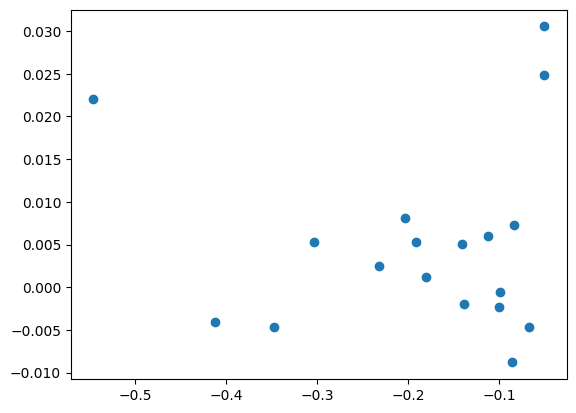

[[3.16059976e-05 1.29769244e-04]
 [1.29769244e-04 6.57113185e-04]]
Mexico !!!
Mexico ???


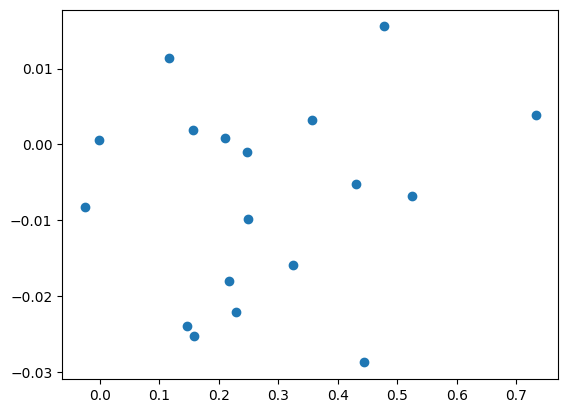

[[ 2.25000297e-05 -5.10520420e-05]
 [-5.10520420e-05  1.87140096e-04]]
Mozambique !!!
Mozambique ???


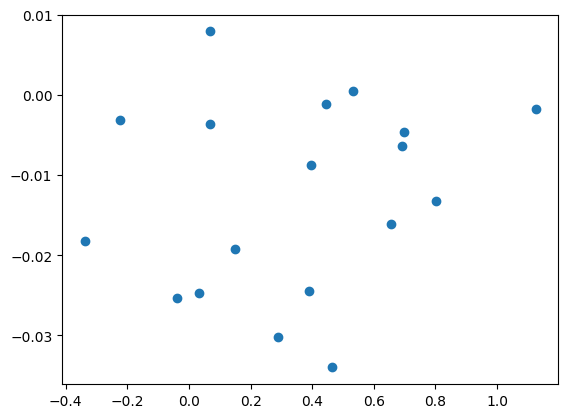

[[ 1.37012177e-05 -1.44318016e-05]
 [-1.44318016e-05  2.95341888e-05]]
Myanmar !!!
Myanmar ???


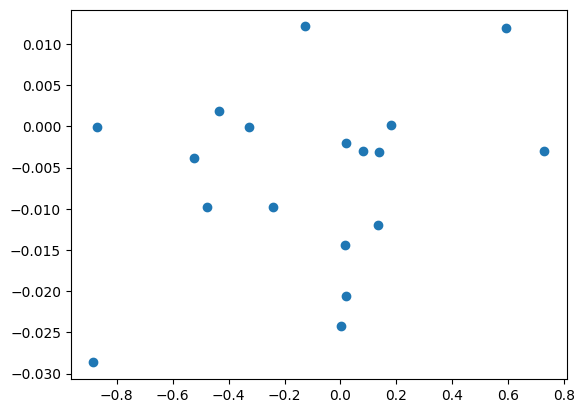

[[5.70637364e-06 1.29638537e-06]
 [1.29638537e-06 3.75117685e-05]]
Netherlands !!!
Netherlands ???


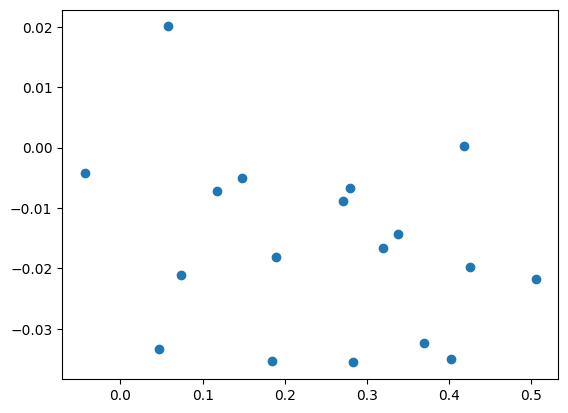

[[ 5.27196270e-05 -1.47090413e-04]
 [-1.47090413e-04  5.01210369e-04]]
New Zealand !!!
New Zealand ???


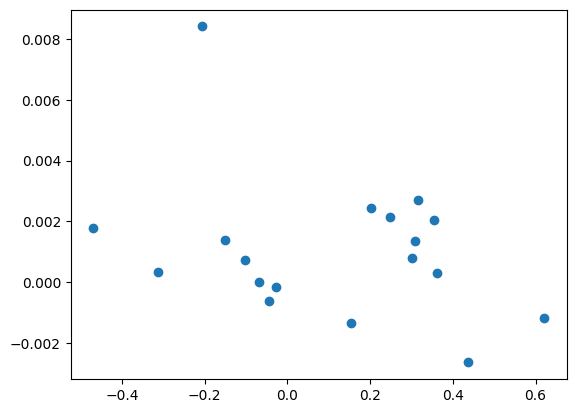

[[ 3.85856896e-07 -7.71763684e-07]
 [-7.71763684e-07  3.26987736e-06]]
Nigeria !!!
Nigeria ???


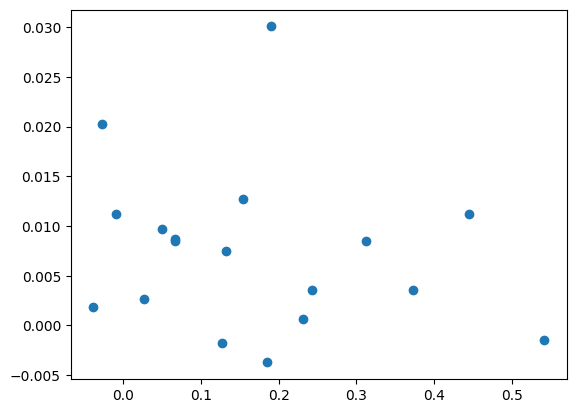

[[ 5.98788865e-06 -1.39086652e-05]
 [-1.39086652e-05  7.51782809e-05]]
Norway, Svalbard and Jan Mayen !!!
Norway, Svalbard and Jan Mayen ???


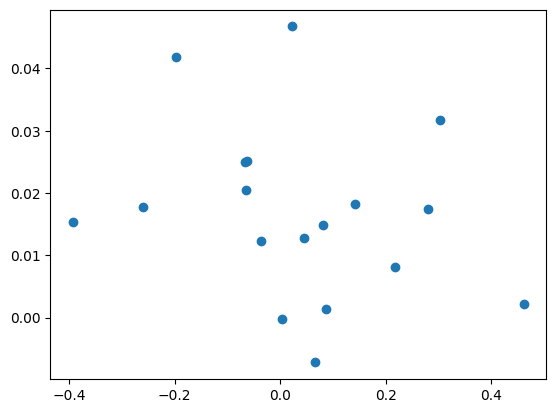

[[ 9.88309348e-06 -6.01853251e-06]
 [-6.01853251e-06  1.55280325e-04]]
Oman !!!
Oman ???


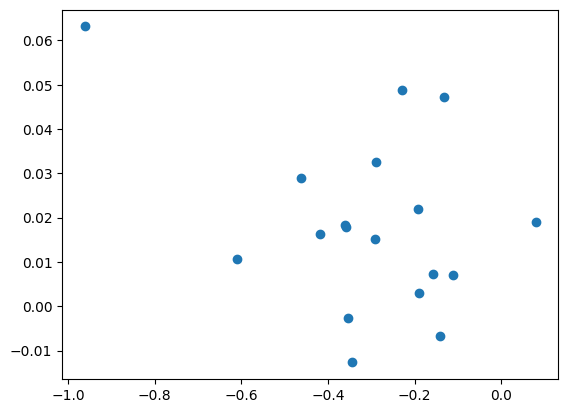

[[5.90467100e-05 1.38742728e-04]
 [1.38742728e-04 4.67266912e-04]]
Other Asia, not elsewhere specified !!!
Other Asia, not elsewhere specified ???


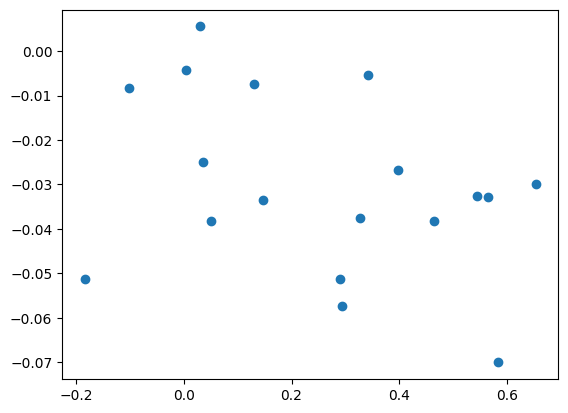

[[ 5.52003275e-05 -1.21190936e-04]
 [-1.21190936e-04  3.92441371e-04]]
Pakistan !!!
Pakistan ???


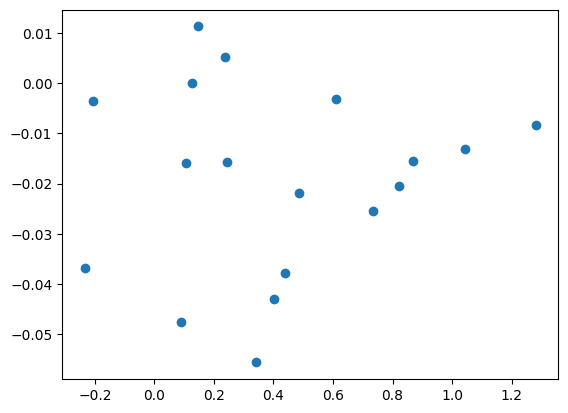

[[ 4.64629656e-05 -4.64620609e-05]
 [-4.64620609e-05  6.18765903e-05]]
Peru !!!
Peru ???


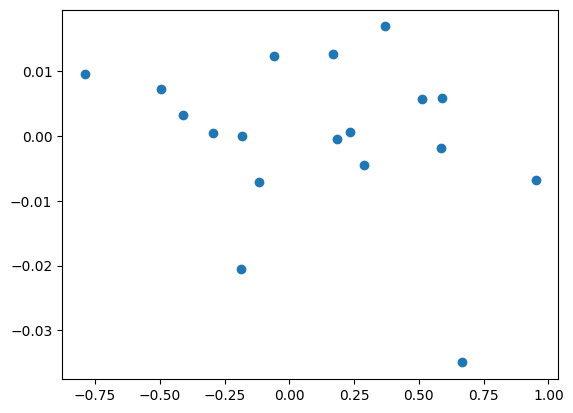

[[6.07271397e-06 4.08893234e-06]
 [4.08893234e-06 3.17365962e-05]]
Poland !!!
Poland ???


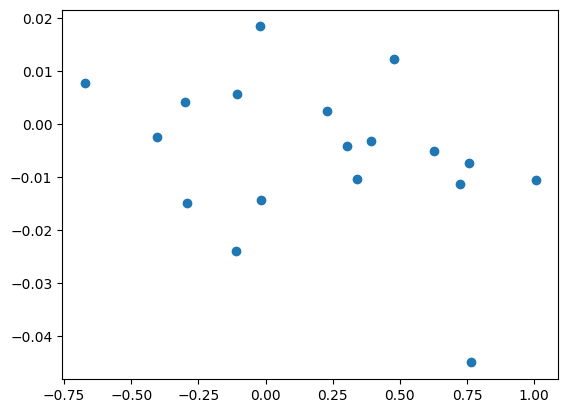

[[ 9.11121841e-06 -2.92408861e-06]
 [-2.92408861e-06  3.88568550e-05]]
Portugal !!!
Portugal ???


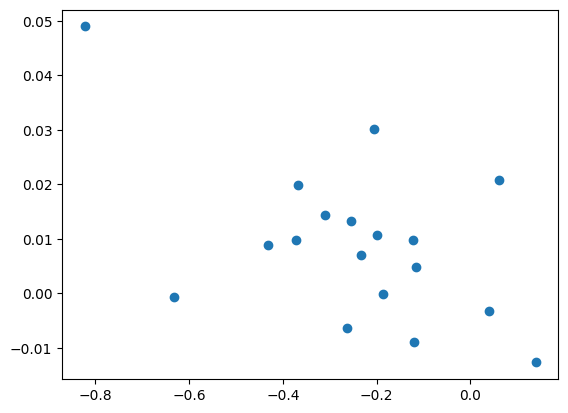

[[2.07313924e-05 6.50738758e-05]
 [6.50738758e-05 3.23552660e-04]]
Republic of Korea !!!
Republic of Korea ???


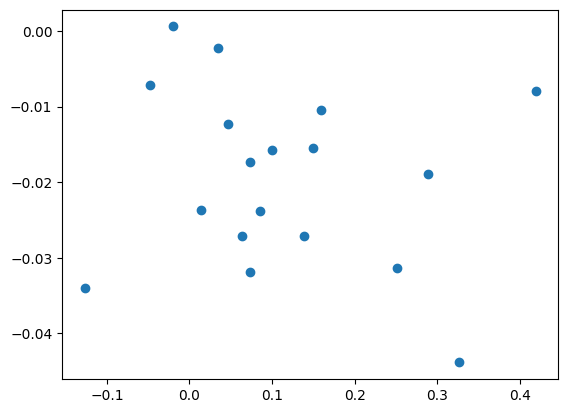

[[ 1.57688641e-05 -7.95827352e-05]
 [-7.95827352e-05  7.41006048e-04]]
Republic of Moldova !!!
Republic of Moldova ???


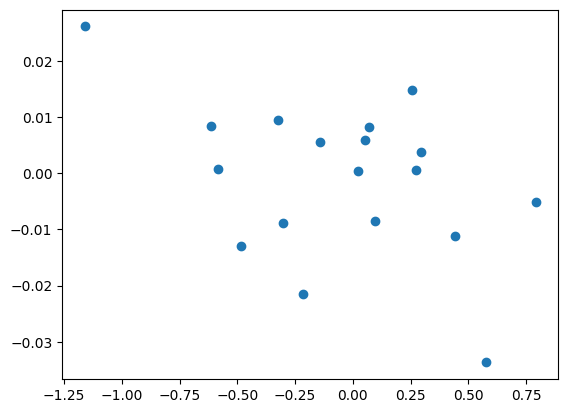

[[8.39225533e-06 4.36231410e-06]
 [4.36231410e-06 4.07397585e-05]]
Romania !!!
Romania ???


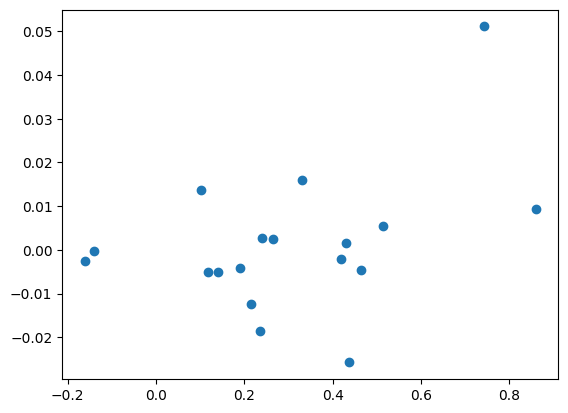

[[ 1.64143253e-05 -4.92015577e-05]
 [-4.92015577e-05  2.74127741e-04]]
Russian Federation !!!
Russian Federation ???


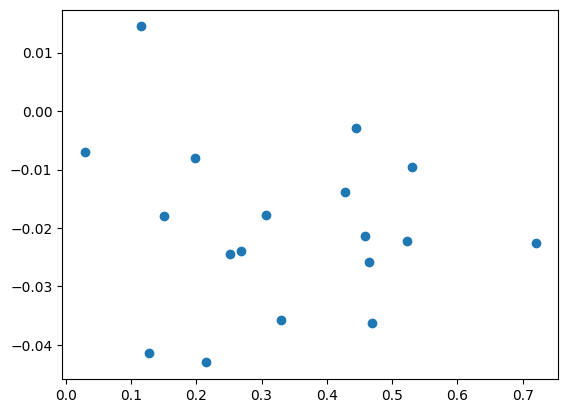

[[ 7.41772539e-05 -1.53390169e-04]
 [-1.53390169e-04  3.50471052e-04]]
Samoa !!!
Samoa ???


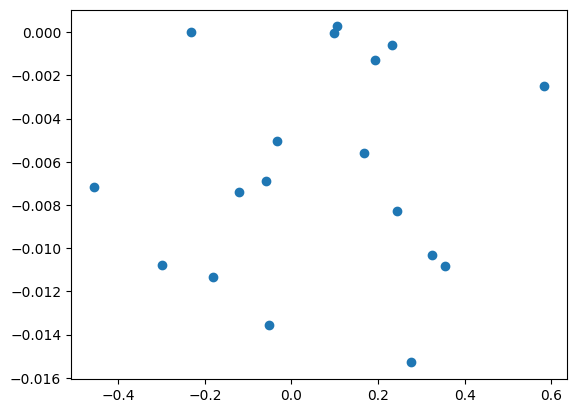

[[ 1.23238834e-06 -6.71289772e-08]
 [-6.71289772e-08  1.37031073e-05]]
Sao Tome and Principe !!!
Sao Tome and Principe ???


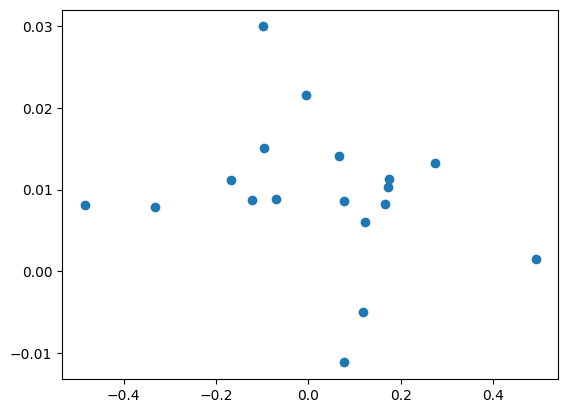

[[ 4.03955921e-06 -1.73750902e-06]
 [-1.73750902e-06  3.58157356e-05]]
Saudi Arabia !!!
Saudi Arabia ???


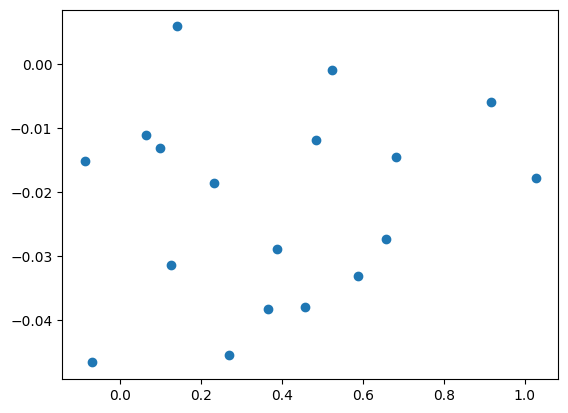

[[ 3.53419268e-05 -4.85607275e-05]
 [-4.85607275e-05  9.20563927e-05]]
Senegal !!!
Senegal ???


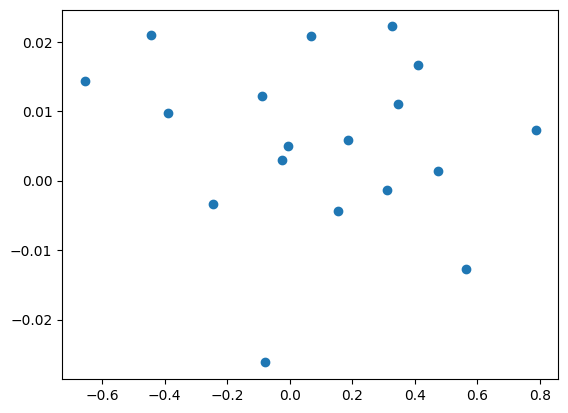

[[ 8.51722809e-06 -4.80492242e-06]
 [-4.80492242e-06  3.69048348e-05]]
Serbia !!!
Serbia ???


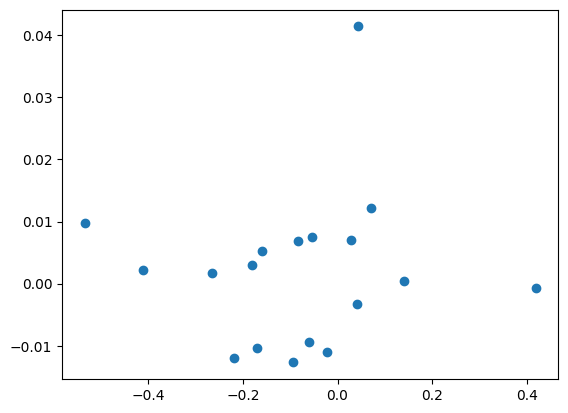

[[1.09655906e-05 2.00027230e-05]
 [2.00027230e-05 9.96423519e-05]]
Singapore !!!
Singapore ???


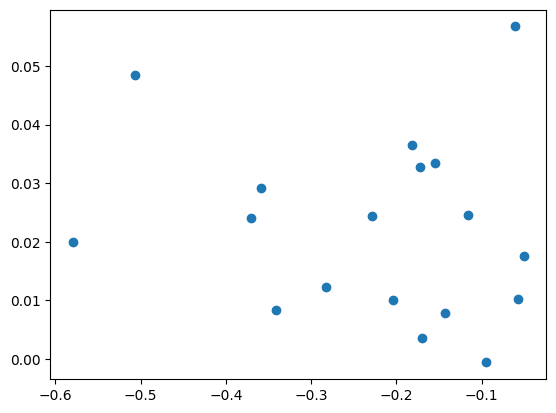

[[5.63041379e-05 1.70772479e-04]
 [1.70772479e-04 6.49670061e-04]]
Slovakia !!!
Slovakia ???


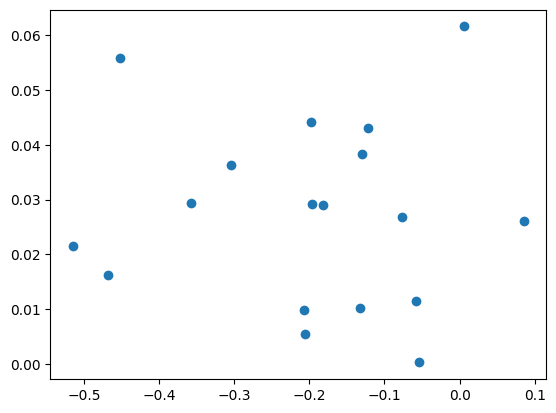

[[4.83779534e-05 1.47077786e-04]
 [1.47077786e-04 6.40803612e-04]]
Slovenia !!!
Slovenia ???


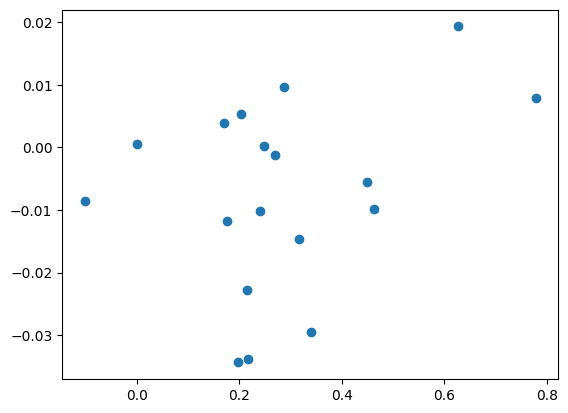

[[ 2.77922958e-05 -5.45538469e-05]
 [-5.45538469e-05  1.75016606e-04]]
South Africa !!!
South Africa ???


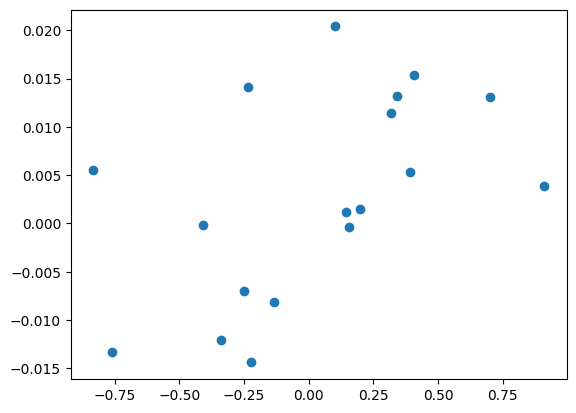

[[ 4.56675494e-06 -3.57350844e-06]
 [-3.57350844e-06  2.12330667e-05]]
Spain !!!
Spain ???


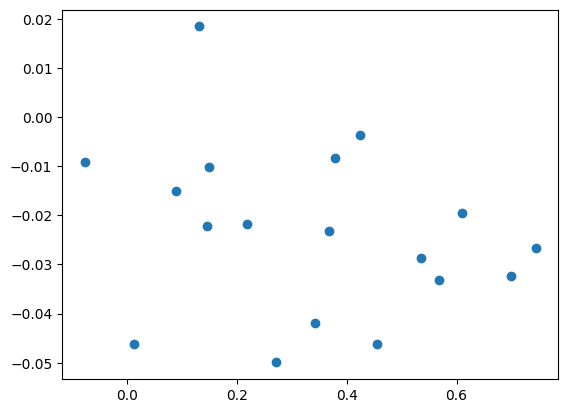

[[ 5.79289295e-05 -9.78490700e-05]
 [-9.78490700e-05  2.01370775e-04]]
Suriname !!!
Suriname ???


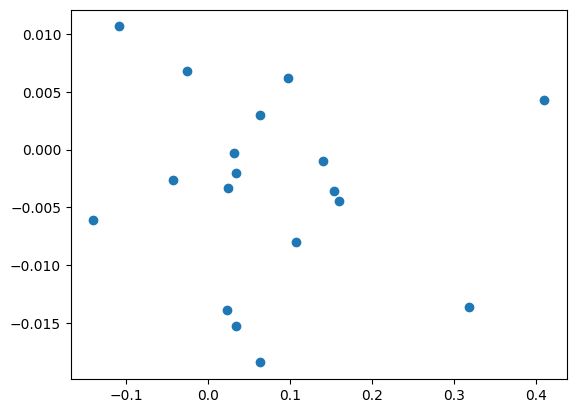

[[ 4.92621700e-06 -1.94888541e-05]
 [-1.94888541e-05  2.51534311e-04]]
Swaziland !!!
Swaziland ???


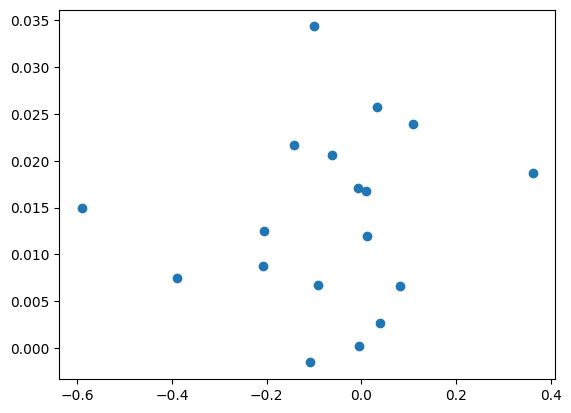

[[5.11260822e-06 4.41085635e-06]
 [4.41085635e-06 3.51195921e-05]]
Sweden !!!
Sweden ???


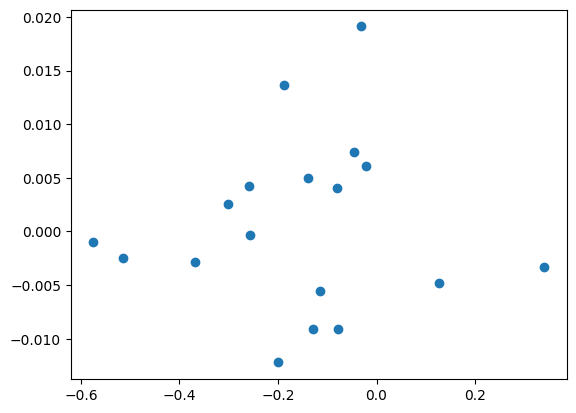

[[5.61844805e-06 9.45290996e-06]
 [9.45290996e-06 2.96284125e-05]]
Switzerland, Liechtenstein !!!
Switzerland, Liechtenstein ???


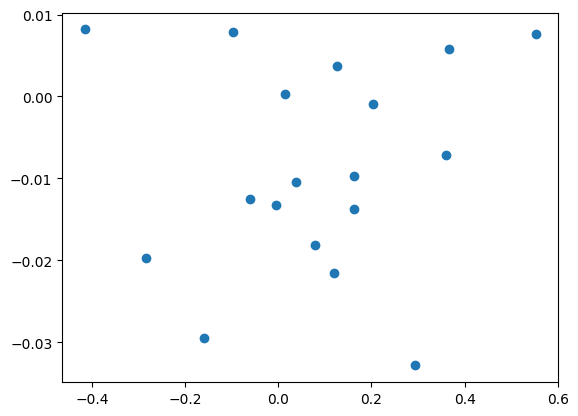

[[ 1.08619250e-05 -2.44215821e-05]
 [-2.44215821e-05  2.41500425e-04]]
The Former Yugoslav Republic of Macedonia !!!
The Former Yugoslav Republic of Macedonia ???


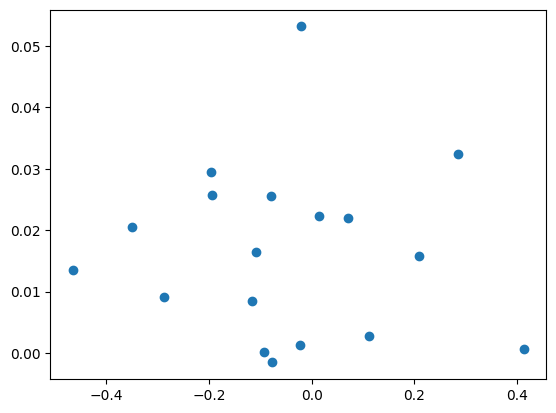

[[1.21238130e-05 2.01226386e-05]
 [2.01226386e-05 1.47615272e-04]]
Trinidad and Tobago !!!
Trinidad and Tobago ???


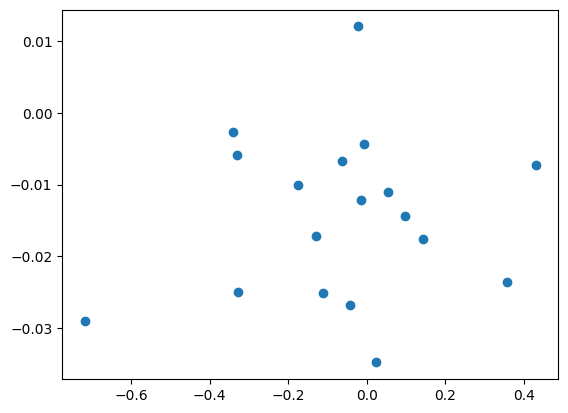

[[7.01299883e-06 3.48778191e-06]
 [3.48778191e-06 8.04424679e-05]]
Tunisia !!!
Tunisia ???


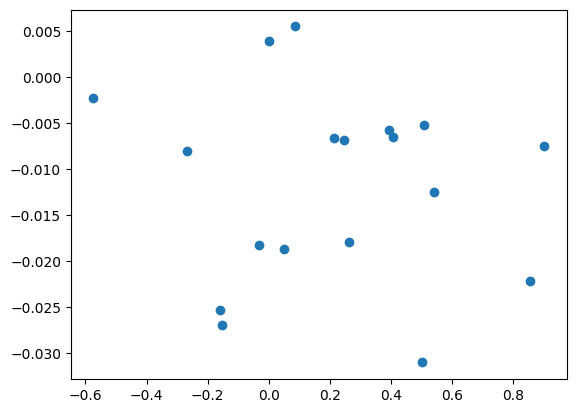

[[ 8.14050460e-06 -9.32186470e-06]
 [-9.32186470e-06  3.21527621e-05]]
Turkey !!!
Turkey ???


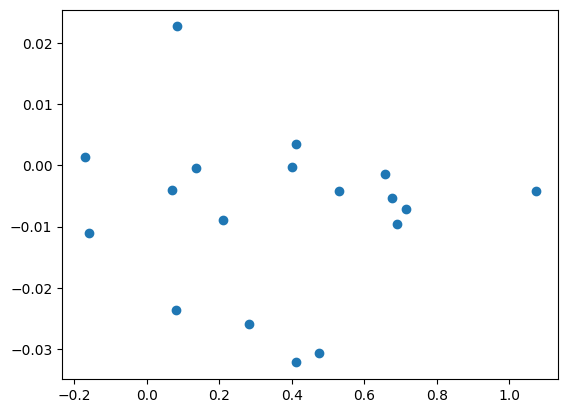

[[ 2.11764810e-05 -2.42887411e-05]
 [-2.42887411e-05  4.43777386e-05]]
Ukraine !!!
Ukraine ???


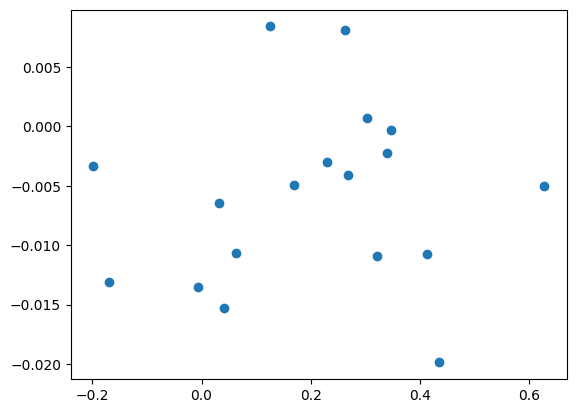

[[ 4.19625241e-06 -7.84594853e-06]
 [-7.84594853e-06  4.77667207e-05]]
United Arab Emirates !!!
United Arab Emirates ???


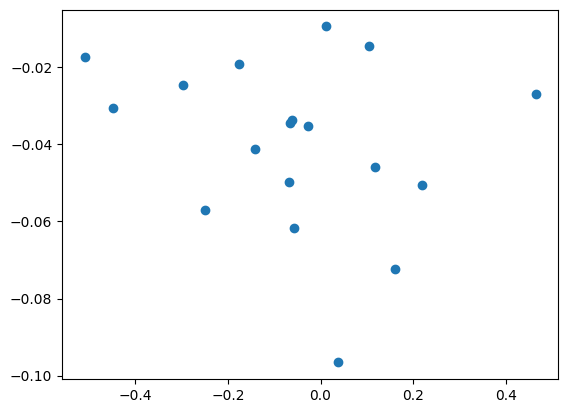

[[3.01468784e-05 6.11015331e-05]
 [6.11015331e-05 3.46027077e-04]]
United Kingdom !!!
United Kingdom ???


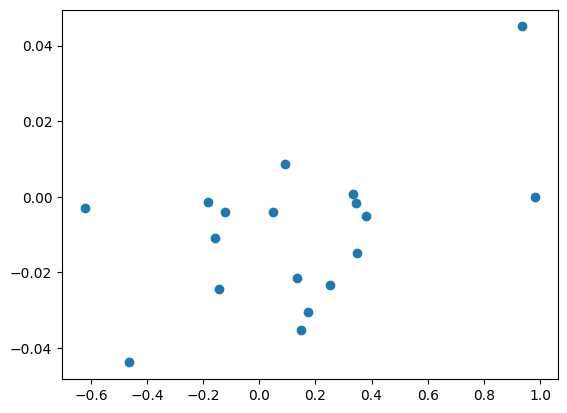

[[ 1.71340262e-05 -1.82053954e-05]
 [-1.82053954e-05  1.77903281e-04]]
USA, Puerto Rico and US Virgin Islands !!!
USA, Puerto Rico and US Virgin Islands ???


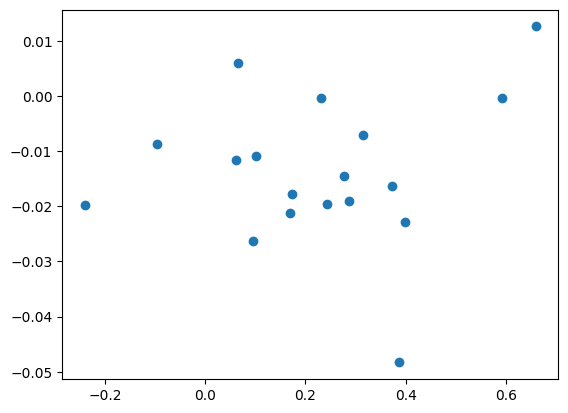

[[ 1.07198288e-05 -2.96487952e-05]
 [-2.96487952e-05  2.35410452e-04]]
Uzbekistan !!!
Uzbekistan ???


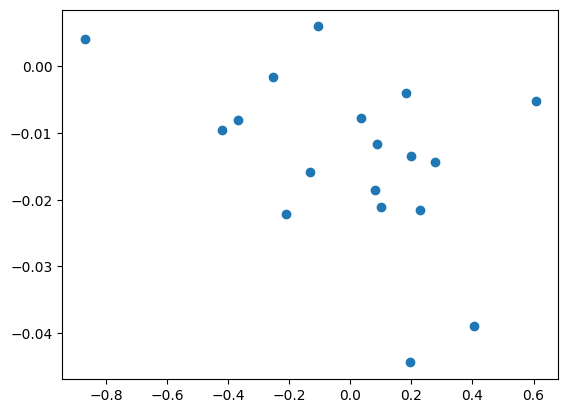

[[7.07847220e-06 1.23215533e-05]
 [1.23215533e-05 6.08848723e-05]]
Viet Nam !!!
Viet Nam ???


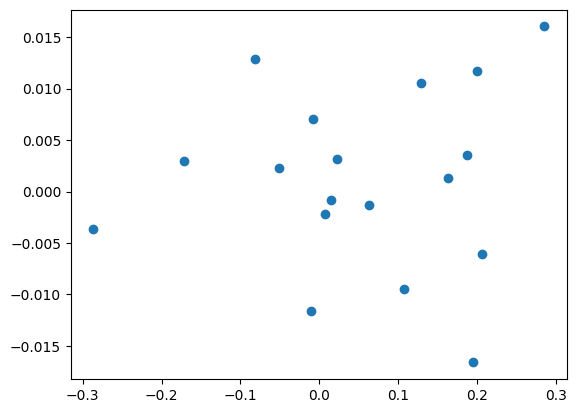

[[3.08227704e-06 2.83453663e-06]
 [2.83453663e-06 1.98454396e-04]]
Zambia !!!
Zambia ???


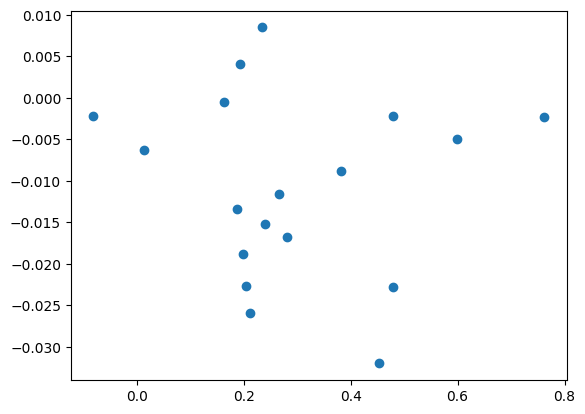

[[ 1.46288260e-05 -3.27208862e-05]
 [-3.27208862e-05  1.26939083e-04]]
Zimbabwe !!!
Zimbabwe ???
                                                    Country Name Country Code  \
Series Name                                                                     
GDP (current US$)                                    Afghanistan          AFG   
GDP (current US$)                                        Albania          ALB   
GDP (current US$)                                        Algeria          DZA   
GDP (current US$)                                 American Samoa          ASM   
GDP (current US$)                                        Andorra          AND   
...                                                          ...          ...   
NaN                                                            0            0   
NaN                                                            0            0   
NaN                                                            0            0   
Data from da

ValueError: ignored

In [51]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))
gdp_raw=pd.read_csv(root_path+'GDP4.csv', index_col=0).fillna(0)
print(gdp_raw)
reg, growth= compute_regress(soi_adi, gdp_raw, country_list, country_list2)
# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()

In [52]:
#soi_adi, gdp_raw, country_list, country_list2
# DOES NOT WORK - TO FIX
compute_regress(soi_adi, gdp_raw, country_list, country_list2)


ValueError: ignored

In [53]:
c= main_country
sorted_x = sorted(soi_adi.items(), key=lambda kv: kv[1], reverse=True)
for i in range(len(sorted_x)):
  print(i, "  ", sorted_x[i])
soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', soi_adi[c],'Growth', growth[c])
for i in growth.keys():
 # if i=='Viet Nam':
  #  i='Vietnam'
  print(i, "\t", growth[i])

0    ('Malaysia', 0.35519060760442434)
1    ('Lithuania', 0.3167161168856192)
2    ('Luxembourg', 0.2503560390249394)
3    ('Republic of Korea', 0.2379434183484369)
4    ('Spain', 0.21292761203756827)
5    ('USA, Puerto Rico and US Virgin Islands', 0.19429202921425703)
6    ('Kenya', 0.18268521155255224)
7    ('El Salvador', 0.16819579516657268)
8    ('Belgium', 0.16750783742323405)
9    ('Malta', 0.16504157719883394)
10    ('Finland', 0.16098684351153314)
11    ('Viet Nam', 0.15515183945007227)
12    ('Romania', 0.14964425862093444)
13    ('Czechia', 0.13490031792036605)
14    ('Russian Federation', 0.09863916035288467)
15    ('Other Asia, not elsewhere specified', 0.07981810952490487)
16    ('Brazil', 0.07323198179796431)
17    ('Indonesia', 0.07287919585348546)
18    ('Estonia', 0.07284591986601752)
19    ('Egypt', 0.0727442819441213)
20    ('Pakistan', 0.07139883684198978)
21    ('Portugal', 0.06494224264274384)
22    ('Germany', 0.058594713725510505)
23    ('China', 0.058478832262

NameError: ignored

SOI w/ Opportunity Gain

In [54]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_18, product_list_18, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_18)
reg_opp.summary()

categorization verified
[('Angola', 1.0), ('Argentina', 1.0), ('Armenia', 1.0), ('Aruba', 1.0), ('Australia', 1.0), ('Austria', 1.0), ('Azerbaijan', 1.0), ('Barbados', 1.0), ('Belarus', 1.0), ('Belgium', 1.0), ('Belize', 1.0), ('Benin', 1.0), ('Bermuda', 1.0), ('Bosnia Herzegovina', 1.0), ('Botswana', 1.0), ('Brazil', 1.0), ('Brunei Darussalam', 1.0), ('Bulgaria', 1.0), ('Burundi', 1.0), ('Cambodia', 1.0), ('Canada', 1.0), ('Cayman Islands', 1.0), ('Chile', 1.0), ('China', 1.0), ('China, Hong Kong Special Administrative Region', 1.0), ('Colombia', 1.0), ('Congo', 1.0), ('Croatia', 1.0), ('Cyprus', 1.0), ('Czechia', 1.0), ('Denmark', 1.0), ('EU-28', 1.0), ('Ecuador', 1.0), ('Egypt', 1.0), ('El Salvador', 1.0), ('Estonia', 1.0), ('Fiji', 1.0), ('Finland', 1.0), ('France, Monaco', 1.0), ('Georgia', 1.0), ('Germany', 1.0), ('Greece', 1.0), ('Grenada', 1.0), ('Guyana', 1.0), ('Hungary', 1.0), ('Iceland', 1.0), ('India', 1.0), ('Indonesia', 1.0), ('Ireland', 1.0), ('Israel', 1.0), ('Italy', 

ValueError: ignored

In [ ]:
#print(df1_cl)
#print(df2_cl)
#print(df1_cl-df2_cl)
exp_change= (df1_cl-df3_cl)/df1_cl
soi_exp= compute_soi_exp(country_list, product_list,country_list_18, product_list_18, opportunity_gain, exp_change)
print(sorted(soi_exp.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_exp= compute_regress(soi_exp, gdp_raw, country_list, country_list_18)
reg_exp.summary()

categorization verified


ValueError: ignored

# End

In [55]:
print(np.sort(list(soi_adi.keys())))
print(np.sort(country_list))
print(np.sort(country_list2))

['Angola' 'Argentina' 'Armenia' 'Aruba' 'Australia' 'Austria' 'Azerbaijan'
 'Barbados' 'Belarus' 'Belgium' 'Belize' 'Benin' 'Bermuda'
 'Bosnia Herzegovina' 'Botswana' 'Brazil' 'Brunei Darussalam' 'Bulgaria'
 'Burundi' 'Cambodia' 'Canada' 'Cayman Islands' 'Chile' 'China'
 'China, Hong Kong Special Administrative Region' 'Colombia' 'Congo'
 'Croatia' 'Cyprus' 'Czechia' 'Denmark' 'EU-28' 'Ecuador' 'Egypt'
 'El Salvador' 'Estonia' 'Fiji' 'Finland' 'France, Monaco' 'Georgia'
 'Germany' 'Greece' 'Grenada' 'Guyana' 'Hungary' 'Iceland' 'India'
 'Indonesia' 'Ireland' 'Israel' 'Italy' 'Japan' 'Jordan' 'Kenya'
 'Kyrgyzstan' 'Latvia' 'Lebanon' 'Lithuania' 'Luxembourg' 'Madagascar'
 'Malaysia' 'Malta' 'Mexico' 'Mozambique' 'Myanmar' 'Netherlands'
 'New Zealand' 'Nigeria' 'Norway, Svalbard and Jan Mayen' 'Oman'
 'Other Asia, not elsewhere specified' 'Pakistan' 'Peru'
 'Plurinational State of Bolivia' 'Poland' 'Portugal' 'Republic of Korea'
 'Republic of Moldova' 'Romania' 'Russian Federation' 'Samoa